# Lista 4 de MLG

- Lara e Marcelo

#### Umas funções auxiliares para reutilizar código nos exercícios


In [2]:
diag_glm <- function(fit, k = 3, titulo = "") {
  h  <- hatvalues(fit)
  td <- rstandard(fit, type = "deviance")   # componente do desvio padronizado
  ck <- cooks.distance(fit)
  p <- length(coef(fit)); n <- length(h)
  rot <- function(x, y, v) { d <- order(abs(v), decreasing = TRUE)[1:k]; text(x[d], y[d], labels = d, pos = 3, cex = 0.8) }
  par(mfrow = c(2, 2))
  plot(fitted(fit), h, xlab = "Valores ajustados", ylab = "Alavanca", pch = 16, main = titulo)
  abline(h = 2 * p / n, lty = 2); rot(fitted(fit), h, h)
  plot(td, xlab = "Índice", ylab = "Resíduo do desvio padronizado", pch = 16, ylim = range(td, -3, 3))
  abline(h = c(-2, 0, 2), lty = c(2, 3, 2)); rot(seq_along(td), td, td)
  plot(ck, xlab = "Índice", ylab = "Distância de Cook", pch = 16); rot(seq_along(ck), ck, ck)
  plot(predict(fit), td, xlab = "Preditor linear", ylab = "Resíduo do desvio padronizado", pch = 16)
  abline(h = c(-2, 0, 2), lty = c(2, 3, 2)); lines(lowess(predict(fit), td), col = "red")
  par(mfrow = c(1, 1))
  cat("Referência 2p/n =", round(2 * p / n, 3), "\n")
  invisible(data.frame(h = h, td = td, cook = ck))
} # isso retornar um painel 2x2 de gráficos de diagnóstico do modelo ajustado
  # tem alavanca, resíduo de desvio adronizado (tDi), cook, e tDi vs preditor linear. 

envelope_glm <- function(fit, nsim = 100, main = "Envelope", semente = 123) {
  set.seed(semente)
  td <- rstandard(fit, type = "deviance")
  n <- length(td); X <- model.matrix(fit); mu <- fitted(fit)
  off <- if (is.null(fit$offset)) rep(0, n) else fit$offset
  nb <- inherits(fit, "negbin"); fam <- family(fit)$family
  e <- matrix(NA, n, nsim)
  for (i in 1:nsim) {
    if (nb) {
      ys <- rnegbin(n, mu = mu, theta = fit$theta)
      fs <- tryCatch(suppressWarnings(glm.nb(ys ~ X - 1 + offset(off))), error = function(err) NULL)
    } else if (fam == "poisson") {
      ys <- rpois(n, mu)
      fs <- suppressWarnings(glm(ys ~ X - 1, family = family(fit), offset = off))
    } else if (fam == "binomial") {
      m <- fit$prior.weights; ys <- rbinom(n, m, mu)
      fs <- suppressWarnings(glm(cbind(ys, m - ys) ~ X - 1, family = family(fit), offset = off))
    }
    if (!is.null(fs)) e[, i] <- sort(rstandard(fs, type = "deviance"))
  }
  e <- e[, colSums(is.na(e)) == 0, drop = FALSE]
  lim <- t(apply(e, 1, function(x) c(min(x), median(x), max(x))))
  q <- qnorm((1:n - 0.375) / (n + 0.25))
  tds <- sort(td)
  fora <- sum(tds < lim[, 1] | tds > lim[, 3]) #quantidade de resíduos fora do envelope
  plot(q, tds, xlab = "Percentil da N(0,1)", ylab = "Componente do desvio padronizado",
       ylim = range(tds, lim), pch = 16, main = main)
  lines(q, lim[, 1]); lines(q, lim[, 3]); lines(q, lim[, 2], lty = 2)
  cat("Pontos fora do envelope:", fora, "de", n, sprintf("(%.1f%%)\n", 100 * fora / n))
  invisible(fora)
} # gráfico normal de probabilidade com envelope simulado.

## Ex 1. 
Faça ex5 do cap 5. Análise de diagnóstico completa. Usa o arquivo `nasal.txt`. É sobre associação entre a taxa anual de câncer nasal e covariáveis, que são: idade (4 níveis), ano de 1º emprego (4 níveis também), tempo decorrido no 1º emprego (5 níveis). Temos o números de casos de câncer nasal e o total de pessoas-anos para cada combinação dos fatores.

In [3]:
#bibliotecas
library(MASS)  
library(gamlss)  

Carregando pacotes exigidos: splines

Carregando pacotes exigidos: gamlss.data


Anexando pacote: 'gamlss.data'


O seguinte objeto é mascarado por 'package:datasets':

    sleep


Carregando pacotes exigidos: gamlss.dist

Carregando pacotes exigidos: nlme

Carregando pacotes exigidos: parallel

 **********   GAMLSS Version 5.5-0  ********** 

For more on GAMLSS look at https://www.gamlss.com/

Type gamlssNews() to see new features/changes/bug fixes.




In [4]:
caminho <- "C:/Users/Marcelo/Downloads/uns pdfs/ufscar/2026 02/MLG/Lista 4/"

nasal <- read.table(paste0(caminho, "L4-Q1-C5-EX5-nasal.txt"), header = TRUE)

nasal$idade = factor(nasal$idade)
nasal$ano = factor(nasal$ano)
nasal$tempo = factor(nasal$tempo)

In [5]:
summary(nasal)

 idade  ano    tempo      casos            panos         
 1:19   1:15   1:12   Min.   :0.0000   Min.   :   2.166  
 2:19   2:19   2:16   1st Qu.:0.0000   1st Qu.:  51.145  
 3:18   3:18   3:16   Median :0.0000   Median : 151.760  
 4:15   4:19   4:16   Mean   :0.7746   Mean   : 214.506  
               5:11   3rd Qu.:1.0000   3rd Qu.: 273.623  
                      Max.   :5.0000   Max.   :1088.072  

As estatísticas acima mostram que temos 71 combinações que é diferente de 4*4*5=80. Isso quer dizer que algumas combinações (9 no total) de `idade x ano x tempo` não existem. Alem disso tem muitos zeros na coluna de casos (a maioria tem 0 ou só 1 caso), e `panos` varia muito (cada combinação na amostra tem quantidade diferente de pessoas).

Os códigos que vieram no enunciado sugerem que vamos usar o modelo com dist. Poisson, ligação log, e o log(panos) como offset (e aditivo nos 3 fatores). Daí o modelo fica do tipo: $Y_{ijk} \sim Poisson (\mu_{ijk})$, com $$\log \mu_{ijk} = \beta_{0} + \beta_{1i} + \beta_{2j} + \beta_{3k} + \log(panos)$$

Assim $e^{\beta_{1i}}$, $e^{\beta_{2j}}$ e $e^{\beta_{3k}}$ são razões de taxas em relação ao nível de referência, que vamos definir como o nível 1.

In [6]:
# podemos fazer uma taxa marginal (caso por 1000 pessoas) de acordo com a idade, ano e tempo.
taxa <- function(x) with (nasal, round(1000 * tapply(casos,x,sum)/tapply(panos,x,sum),2))
list(idade = taxa(nasal$idade), ano = taxa(nasal$ano), tempo = taxa(nasal$tempo))


$idade
    1     2     3     4 
 0.65  2.83  5.12 10.26 

$ano
   1    2    3    4 
5.64 8.95 3.49 1.24 

$tempo
   1    2    3    4    5 
0.39 3.98 3.93 5.28 4.65

Essa parte ainda é a análise descritiva; dá pra ver que a taxa de cancer cresce com `idade` marginalmente (idade quando teve o 1º emprego); e para quem teve nível 1 de `tempo`  a taxa marginal é pequena também.

### 1.1 Ajustando modelo de acordo com dicas que temos no enunciado. (Poisson + ligação log) (usando gamlss e glm)
#### 1.1.1 gamlss

In [7]:
fit1.gamlss<- gamlss(casos ~ idade + ano + tempo + offset(log(panos)), family = PO, data = nasal, trace = FALSE) 
# trace é um parametro que controla a exibição de infos durante o ajuste do modelo. o padrão é TRUE que vai imprimir mensagens detalhadas sobre o progresso do algoritmo
summary(fit1.gamlss)

******************************************************************
Family:  c("PO", "Poisson") 

Call:  gamlss(formula = casos ~ idade + ano + tempo + offset(log(panos)),  
    family = PO, data = nasal, trace = FALSE) 

Fitting method: RS() 

------------------------------------------------------------------
Mu link function:  log
Mu Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) -9.13152    1.31882  -6.924 3.37e-09 ***
idade2       1.61161    0.75165   2.144  0.03609 *  
idade3       2.34833    0.75968   3.091  0.00302 ** 
idade4       3.34327    0.77978   4.287 6.66e-05 ***
ano2         0.59740    0.37173   1.607  0.11328    
ano3        -0.09357    0.48322  -0.194  0.84711    
ano4        -1.14703    0.45372  -2.528  0.01412 *  
tempo2       1.59449    1.04864   1.521  0.13363    
tempo3       1.74015    1.05664   1.647  0.10481    
tempo4       2.33358    1.07154   2.178  0.03337 *  
tempo5       2.59881    1.13441   2.291  0.02550 *  
---
Signif. c

In [8]:
deviance(fit1.gamlss)  # desvio do modelo ajustado

[1] 122.8305

Temos as estimativas dos parâmetros.
- idade: efeito crescente e significativos. $e^{\beta_{12}}$; $e^{\beta_{13}}$; $e^{\beta_{14}}$ ≈ e^(1,61); e^(2,35); e^(3,34). Interpretação: estima-se que a razão de taxas de ocorrência de câncer sejam esses números em relação ao nível de referência (1), mantidas as outras constantes.
- ano: nível 2 e 3 deram não significativos. o beta do nível 3 da covariável ano é bem proximo de 0, ou seja praticamente igual ao nível 1 de referência. o nível 4 deu significativo (e negativo)
- tempo: os betas crescem indicando efeito crescente, mas tem níveis não significativos isoladamente (tempo2 e tempo3).

Outro dados interessantes que a saída nos ofereceu: o global deviance deu 122.83 com 60 g.l e AIC deu 144.8.

#### 1.1.1 glm


In [9]:
# dá para ajustar o mesmo modelo com glm que vimos em aula.
fit1.glm <- glm(casos ~ idade + ano + tempo + offset(log(panos)), family = poisson, data = nasal)
summary(fit1.glm)


Call:
glm(formula = casos ~ idade + ano + tempo + offset(log(panos)), 
    family = poisson, data = nasal)

Coefficients:
            Estimate Std. Error z value Pr(>|z|)    
(Intercept) -9.13152    1.31861  -6.925 4.36e-12 ***
idade2       1.61161    0.75157   2.144  0.03201 *  
idade3       2.34833    0.75960   3.092  0.00199 ** 
idade4       3.34327    0.77970   4.288 1.80e-05 ***
ano2         0.59740    0.37172   1.607  0.10803    
ano3        -0.09357    0.48321  -0.194  0.84645    
ano4        -1.14703    0.45371  -2.528  0.01147 *  
tempo2       1.59449    1.04843   1.521  0.12830    
tempo3       1.74015    1.05643   1.647  0.09952 .  
tempo4       2.33358    1.07134   2.178  0.02939 *  
tempo5       2.59881    1.13422   2.291  0.02195 *  
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for poisson family taken to be 1)

    Null deviance: 126.097  on 70  degrees of freedom
Residual deviance:  51.602  on 60  degrees of freedom
AIC: 144

- D = 51.6 com 60 g.l. Parece que temos um bom ajuste (dispersão estimada = D/gl = 51.6/60 = 0.86, próximo de 1, a variabilidade dos dados parece ser correspondente com o que o modelo prediz). 


In [10]:
drop1(fit1.glm, test = "Chisq")

,Df,Deviance,AIC,LRT,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,51.60155,144.8305,NA,NA
idade,3,86.55667,173.7856,34.95512,1.245140e-07
ano,3,76.65388,163.8828,25.05233,1.505634e-05
tempo,4,62.23442,147.4634,10.63286,3.101525e-02


- TRV: os 3 fatores deram siginificativos ao nível de 5%.

### 1.2 diagnóstico

#### 1.2.1 análise de resíduos com fit1.gamlss

******************************************************************
	 Summary of the Randomised Quantile Residuals
                           mean   =  0.009927364 
                       variance   =  0.8659872 
               coef. of skewness  =  0.1721909 
               coef. of kurtosis  =  2.565999 
Filliben correlation coefficient  =  0.9926718 
******************************************************************


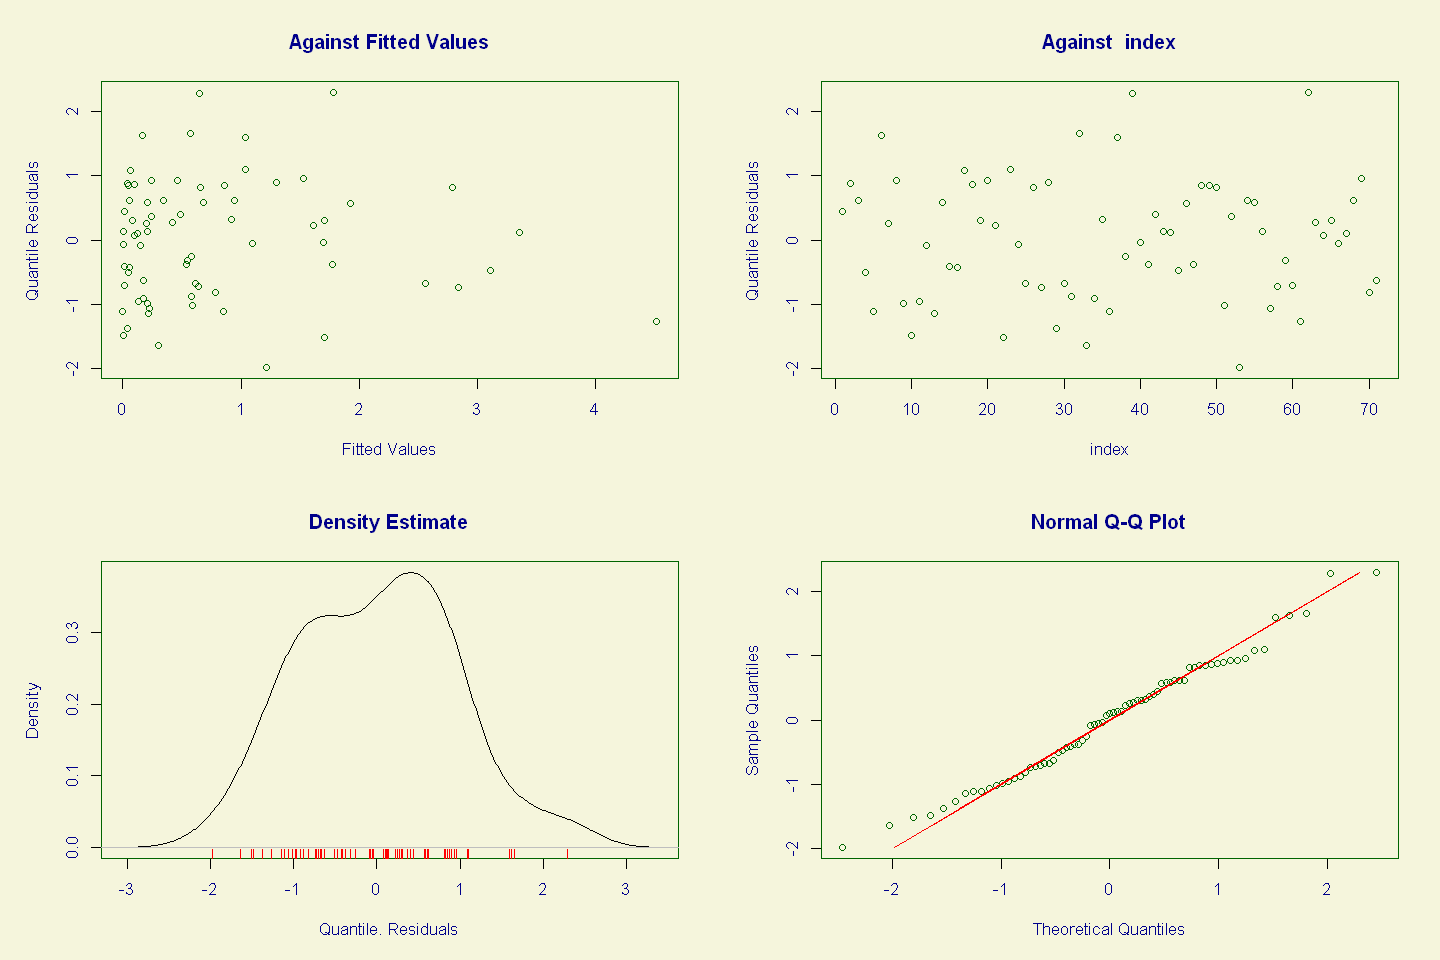

In [11]:
options(repr.plot.width = 12, repr.plot.height = 8) # deixar o gráfico grandinho

# código que veio no enunciado
plot(fit1.gamlss)

Usando a função plot de gamlss temos esses gráficos, que envolve resíduos quantílicos aleatorizados. Fica claro que os resíduos ficam em torno de zero e não parecem ter um padrão contra os valores ajustados (nem com o índice). A densidade é aproximadamente simétrca e o QQplot temos pontos próximos da reta. Graficamente podemos dizer que os resíduos parecem ser compatíveis com N(0,1).

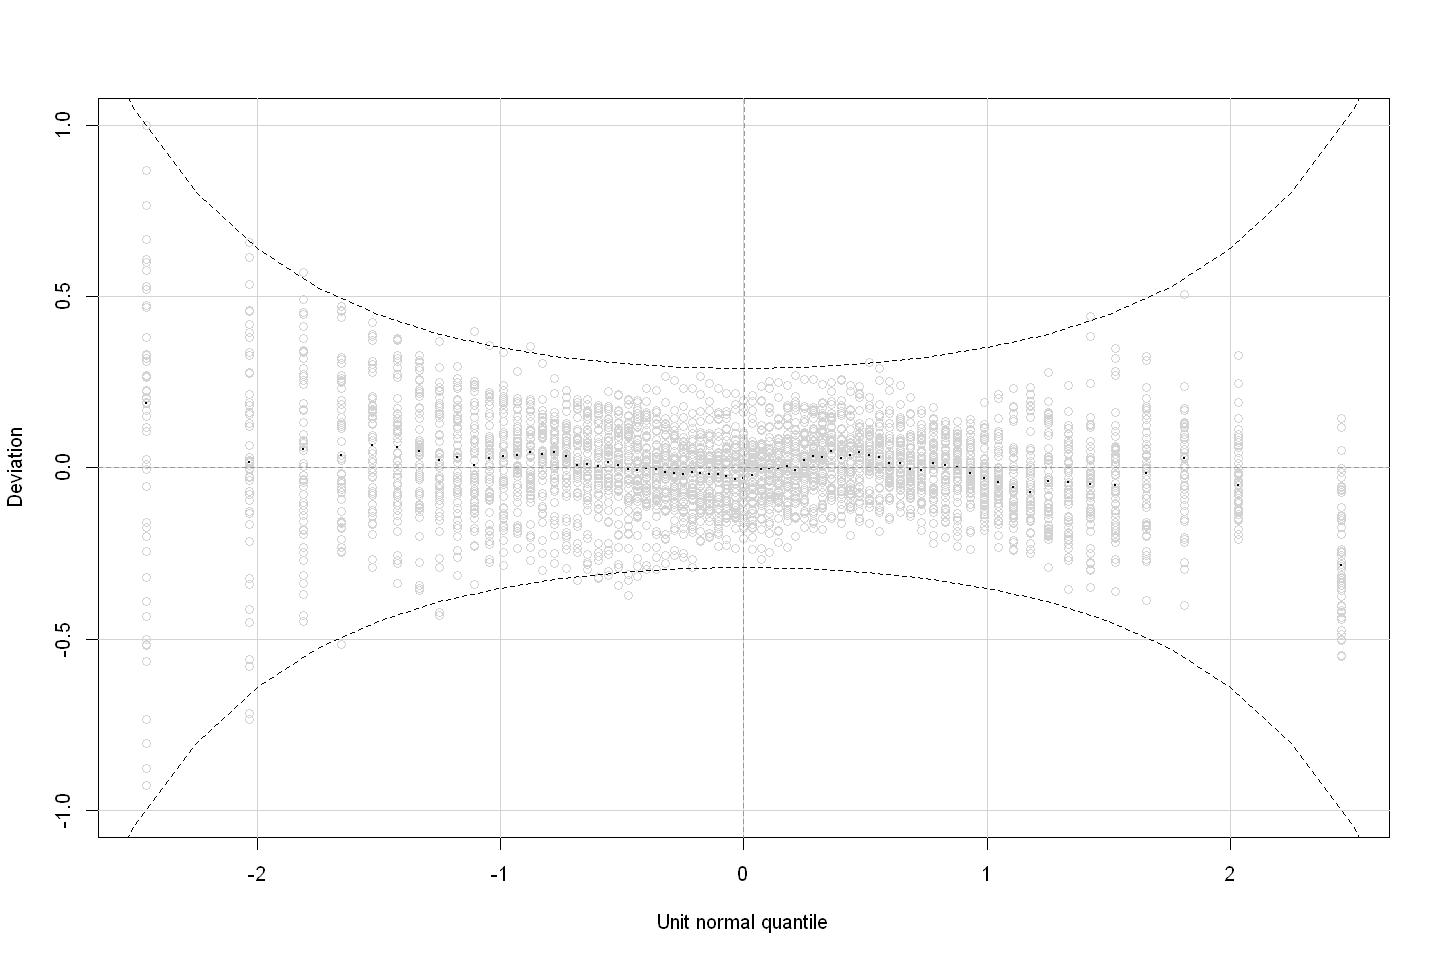

In [12]:
options(repr.plot.width = 12, repr.plot.height = 8) # deixar o gráfico grandinho

# código que veio no enunciado
rqres.plot(fit1.gamlss, howmany = 50, plot = "all")


Nesse gráfico temos 50 realizações de resíduos quatílicos de poisson aleatorizados. Não parece ter um desvio sistemático (vulgo padrão).

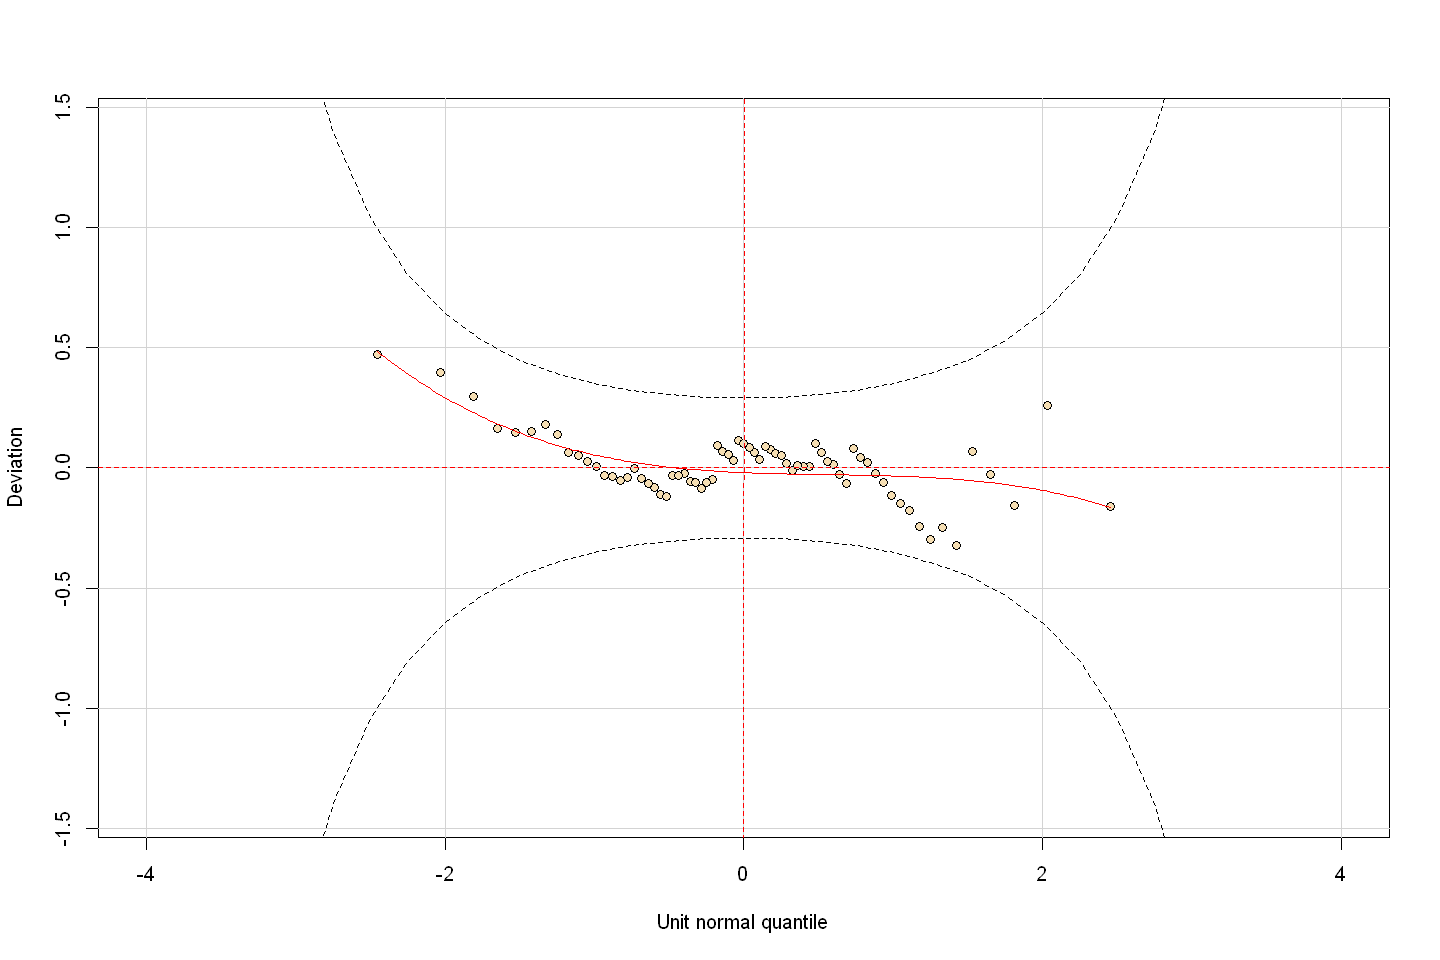

In [13]:
options(repr.plot.width = 12, repr.plot.height = 8) # deixar o gráfico grandinho

# worn plot para gamlss
wp(fit1.gamlss)

No worm plot a maior parte dos pontos estão dentro das curvas de 95%. Tem uma leve forma de S, que sugere que talvez a gente tenha um possível desvio do dados em relação à distribuição que nos esperamos. Mas isso não é uma evidência muito forte.

#### 1.2.2 diagnostico com glm

Referência 2p/n = 0.31 


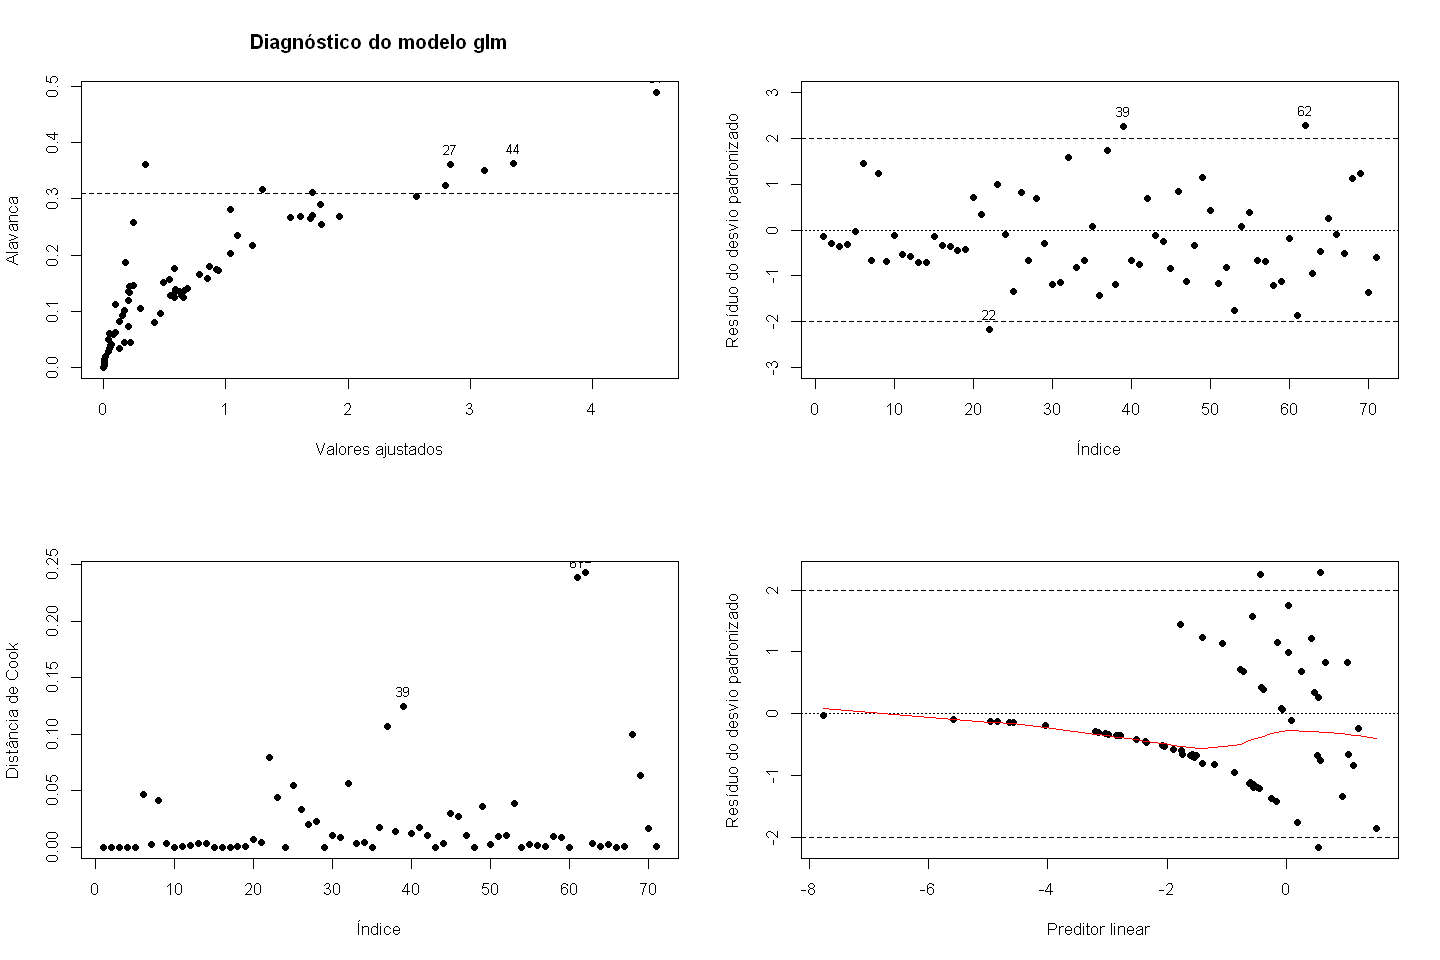

In [14]:
options(repr.plot.width = 12, repr.plot.height = 8) # deixar o gráfico grandinho

#usando a função que criamos no começo desse arquivo
diag_glm(fit1.glm, titulo = "Diagnóstico do modelo glm")

uns comentários sobre esses 4 gráficos:
- Alavanca: alguns pontos estão um pouco acima da linha de referência 2*p/n = 22/71 = 0.31. São os pontos 61,44,27. Porém não é muito preocupante.
- Resíduos padronizados: maioria estão entre -2 e 2. Alguns estão fora (os pontos 62, 39, e 22). Note que a obs 62 nos dá 5 casos de câncer em apenas 56 pessoas-anos.
- Cook: os pontos com a maior distância de cook são 62 e 61 (próximo de 0.24), não são muito grande.
- Resíduo x preditor linear: não temos uma tendência muito claro além da faixa inferior que curva para baixo, que é o padrão feito pelas contagens zeros..

Pontos fora do envelope: 0 de 71 (0.0%)


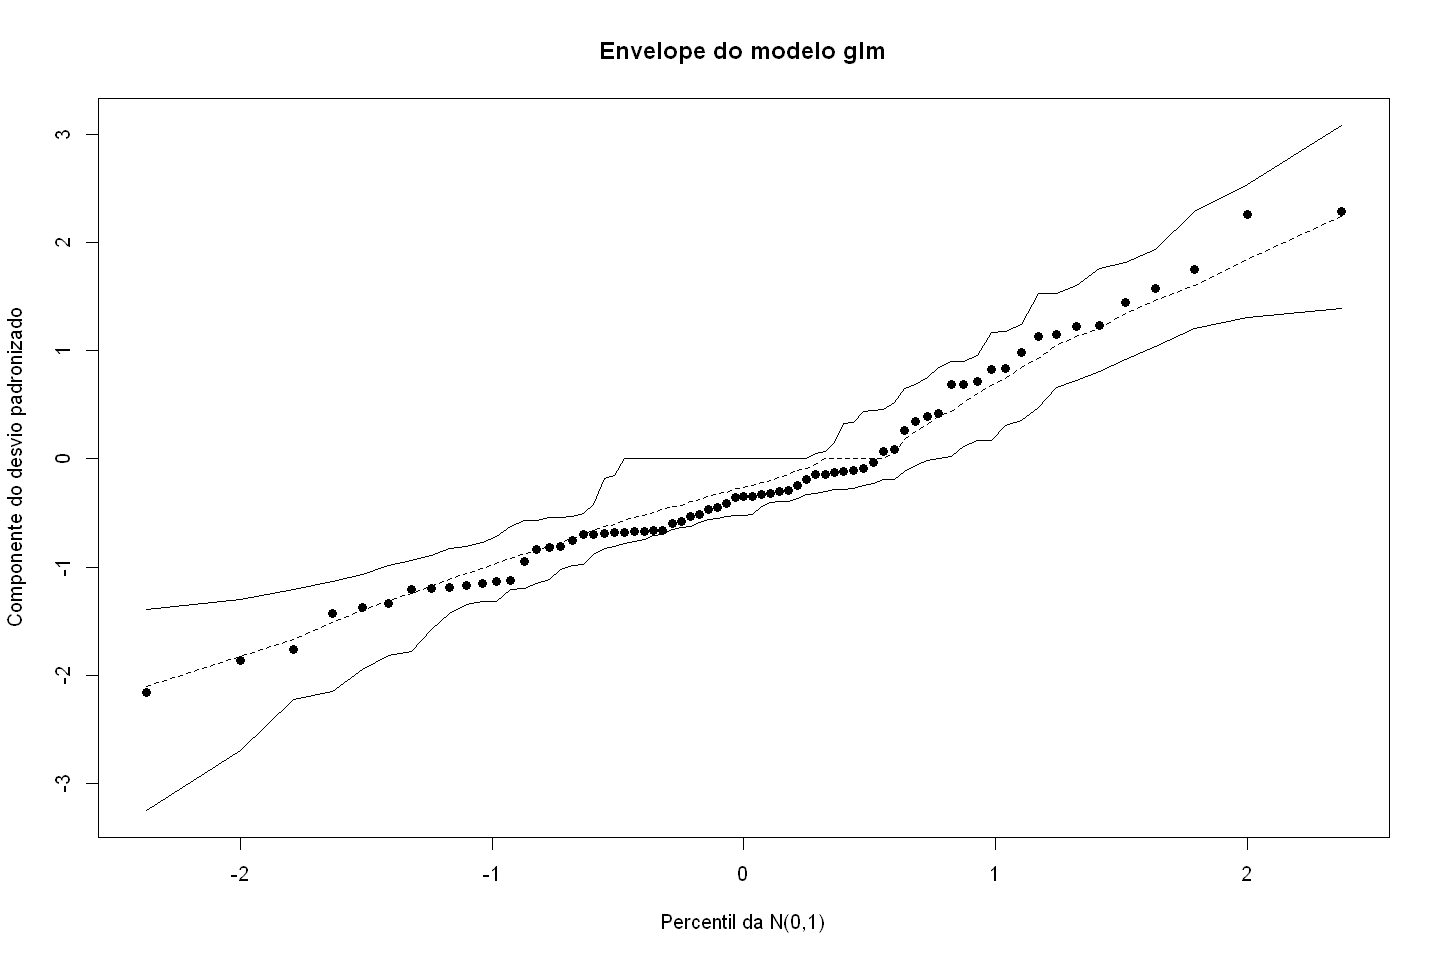

In [15]:
envelope_glm(fit1.glm, nsim = 100, main = "Envelope do modelo glm")

No gráfico todos os pontos estão dentro do envelope. O modelo poisson com ligação log e 3fatores parece bem ajustado.

### 1.3 Agrupando níveis e reajustando.
#### 1.3.1 com gamlss

vimos que o modelo tá bem com poisson e log; vamos agurpar níveis de acordo com a sugestão do enunciado.

In [16]:
nasal$ntempo <- nasal$tempo
levels(nasal$ntempo) <- c("0-39,9", "0-39,9", "0-39,9", "40-49,9", "50+") # nível 1 2 3 se fundiram

nasal$nano <- nasal$ano
levels(nasal$nano) <- c("1902-1919", "1902-1919", "1902-1919", "1920-1924") # nível 1 2 3 se fundiram também

table(nasal$ntempo, nasal$tempo)
table(nasal$nano, nasal$ano)

         
           1  2  3  4  5
  0-39,9  12 16 16  0  0
  40-49,9  0  0  0 16  0
  50+      0  0  0  0 11

           
             1  2  3  4
  1902-1919 15 19 18  0
  1920-1924  0  0  0 19

In [17]:
fit2.gamlss <- gamlss(casos ~ idade + nano + ntempo + offset(log(panos)), family = PO, data = nasal, trace = FALSE)
summary(fit2.gamlss)

******************************************************************
Family:  c("PO", "Poisson") 

Call:  gamlss(formula = casos ~ idade + nano + ntempo + offset(log(panos)),  
    family = PO, data = nasal, trace = FALSE) 

Fitting method: RS() 

------------------------------------------------------------------
Mu link function:  log
Mu Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)    -7.2706     0.7337  -9.910 1.51e-14 ***
idade2          1.6933     0.7437   2.277  0.02614 *  
idade3          2.4050     0.7512   3.202  0.00213 ** 
idade4          3.3321     0.7744   4.303 5.89e-05 ***
nano1920-1924  -1.6821     0.3518  -4.781 1.06e-05 ***
ntempo40-49,9   0.6885     0.3348   2.057  0.04381 *  
ntempo50+       0.9536     0.4995   1.909  0.06072 .  
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

------------------------------------------------------------------
No. of observations in the fit:  71 
Degrees of Freedom for the fit:  7


Como esperado, os parâmetros mudaram com o agrupamento.
- idade: ainda são significativos ao nível de 5%
- ano: o `nano1920-1924` dá signiticativo ao nível de 5%, beta proximos de -1.68
- tempo: o nível ntempo50+ tá não significativo ao nível de 5%.

agora o modelo tem apenas 7 parâmetros e AIC aumentou pouco. 

In [18]:
# trv dos dois modelos gamlss com e sem agrupamento
LR.test(fit2.gamlss, fit1.gamlss)

 Likelihood Ratio Test for nested GAMLSS models. 
 (No check whether the models are nested is performed). 
 
       Null model: deviance= 132.2714 with  7 deg. of freedom 
 Altenative model: deviance= 122.8305 with  11 deg. of freedom 
 
 LRT = 9.440885 with 4 deg. of freedom and p-value= 0.0509762 


Parece que o agrupamento é bom

### 1.3.2 com glm

In [19]:
fit2.glm <- glm(casos ~ idade + nano + ntempo + offset(log(panos)), family = poisson, data = nasal)
c(desvio = deviance(fit2.glm), gl = df.residual(fit2.glm),
  p_valor = 1 - pchisq(deviance(fit2.glm), df.residual(fit2.glm)))

# trv
anova(fit2.glm, fit1.glm, test = "Chisq")

desvio         gl    p_valor 
61.0424402 64.0000000  0.5817428

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,64,61.04244,NA,NA,NA
2,60,51.60155,4,9.440885,0.0509762


- O fit2.glm tem D = 61, e gl é 64: o glm continua bem ajustado.
- TRV para ver se agrupamento funciona: temos uma diferença de 9,44. valor-p deu 5.09%, então ao nível de 5% não rejeitamos a hipotese de que os nívei agrupados têm o mesmo efeito.


Vamos ficar com o agrupamento, que deixa a situação mais simples e interpretável.

### 1.4 diagnóstico dos modelos com agrupamento

Gamlss:

******************************************************************
	 Summary of the Randomised Quantile Residuals
                           mean   =  -0.1132813 
                       variance   =  1.130556 
               coef. of skewness  =  0.08099622 
               coef. of kurtosis  =  3.111942 
Filliben correlation coefficient  =  0.9952037 
******************************************************************


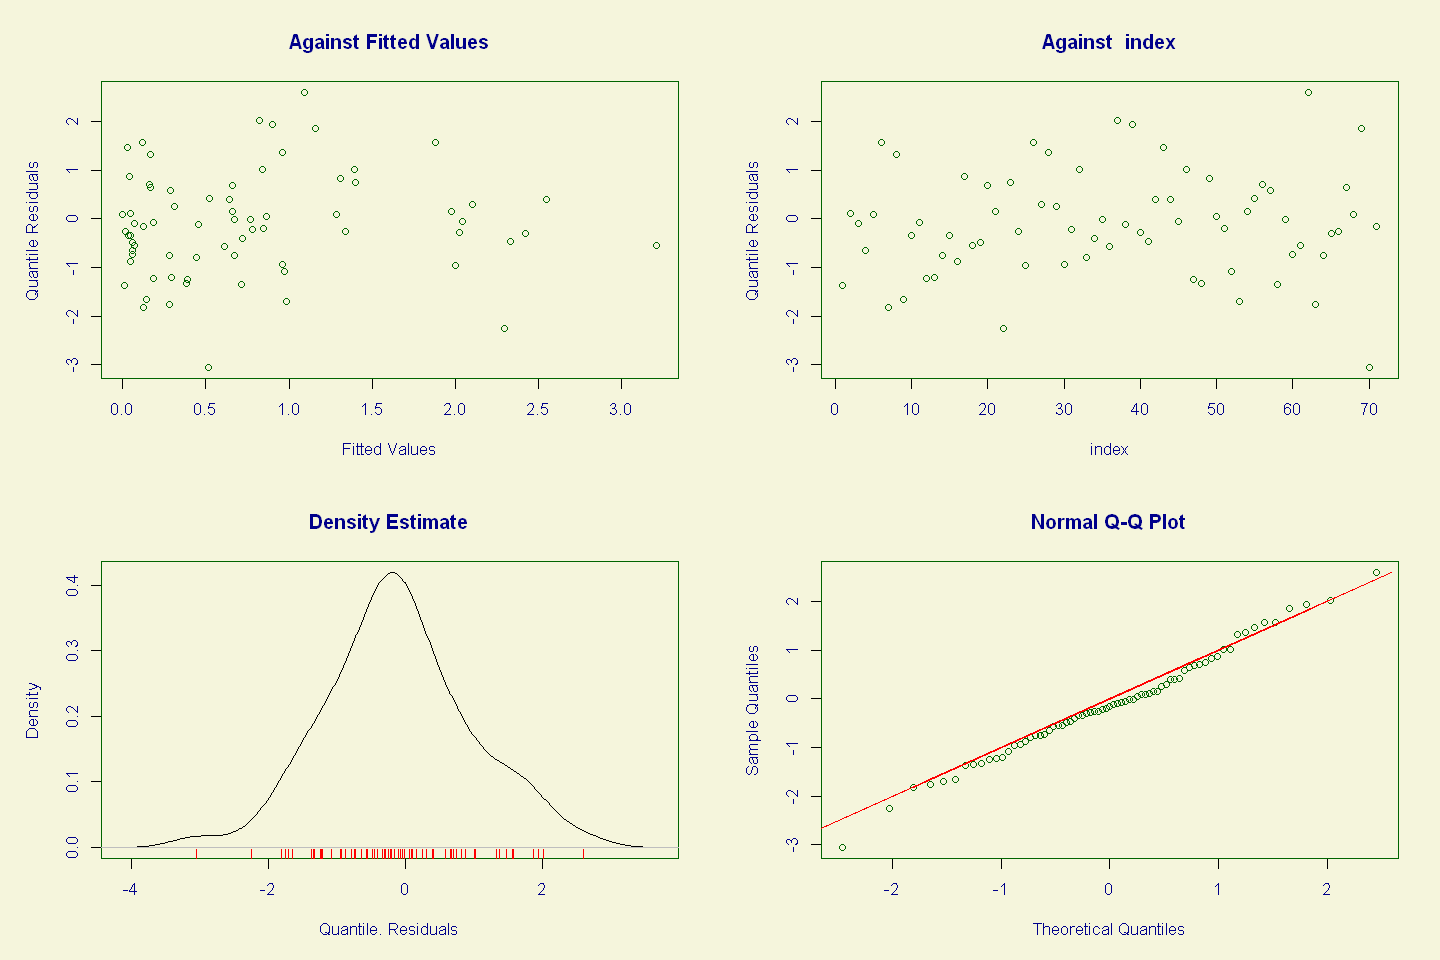

In [20]:
options(repr.plot.width = 12, repr.plot.height = 8) # deixar o gráfico grandinho

plot(fit2.gamlss)

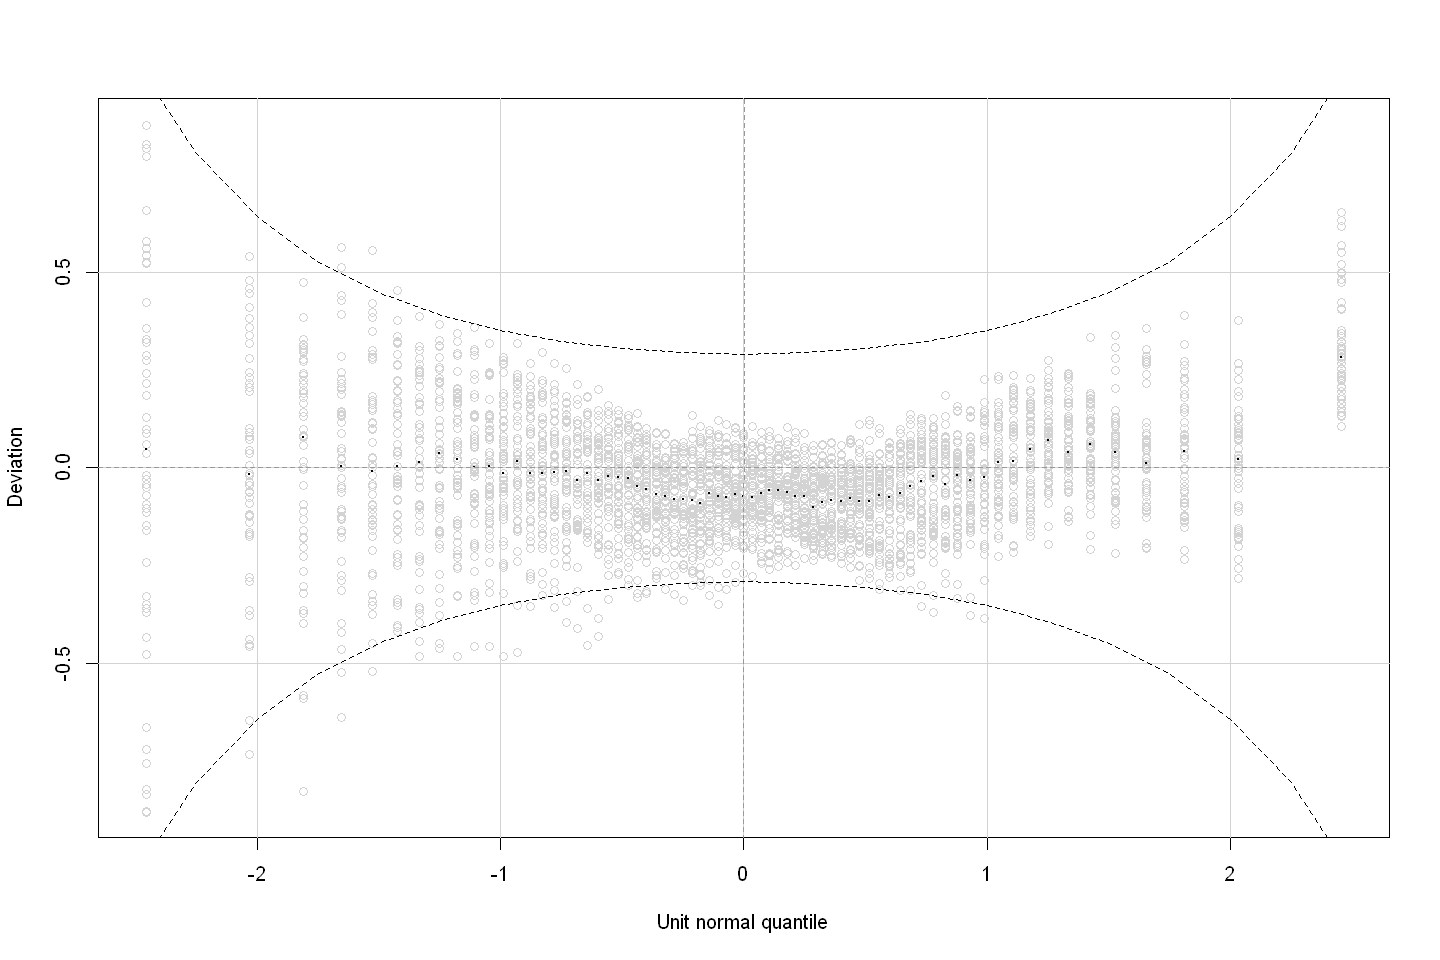

In [21]:
options(repr.plot.width = 12, repr.plot.height = 8) # deixar o gráfico grandinho

rqres.plot(fit2.gamlss, howmany = 50, plot = "all")

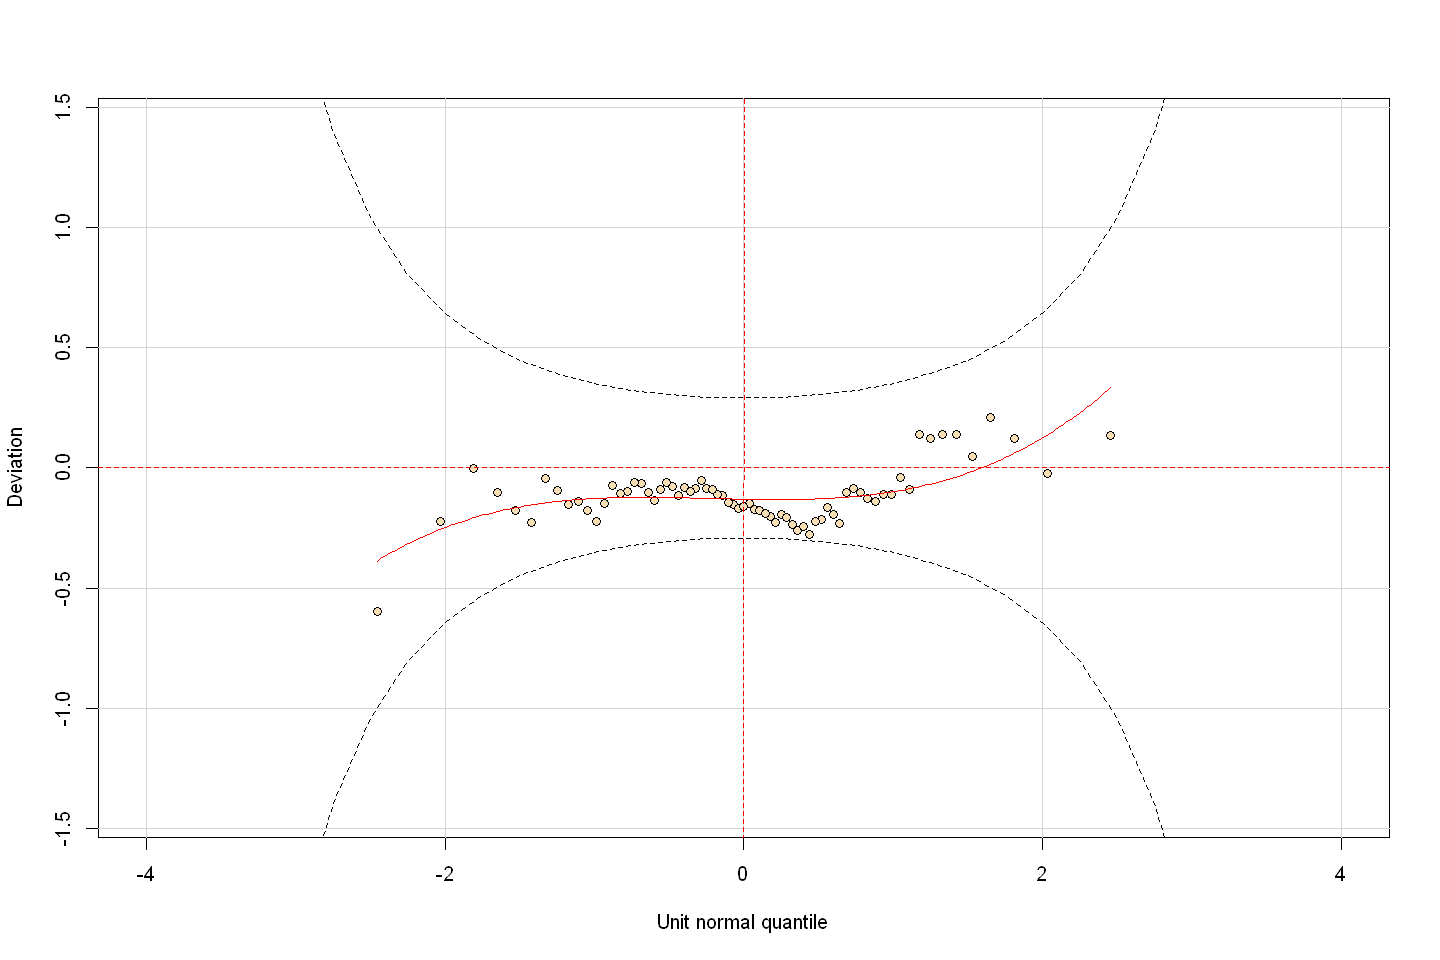

In [22]:
options(repr.plot.width = 12, repr.plot.height = 8) # deixar o gráfico grandinho

wp(fit2.gamlss)

Dá para dizer quase literalmente a mesma coisa de antes. o modelo parece estar bem.

GLM:

Referência 2p/n = 0.197 


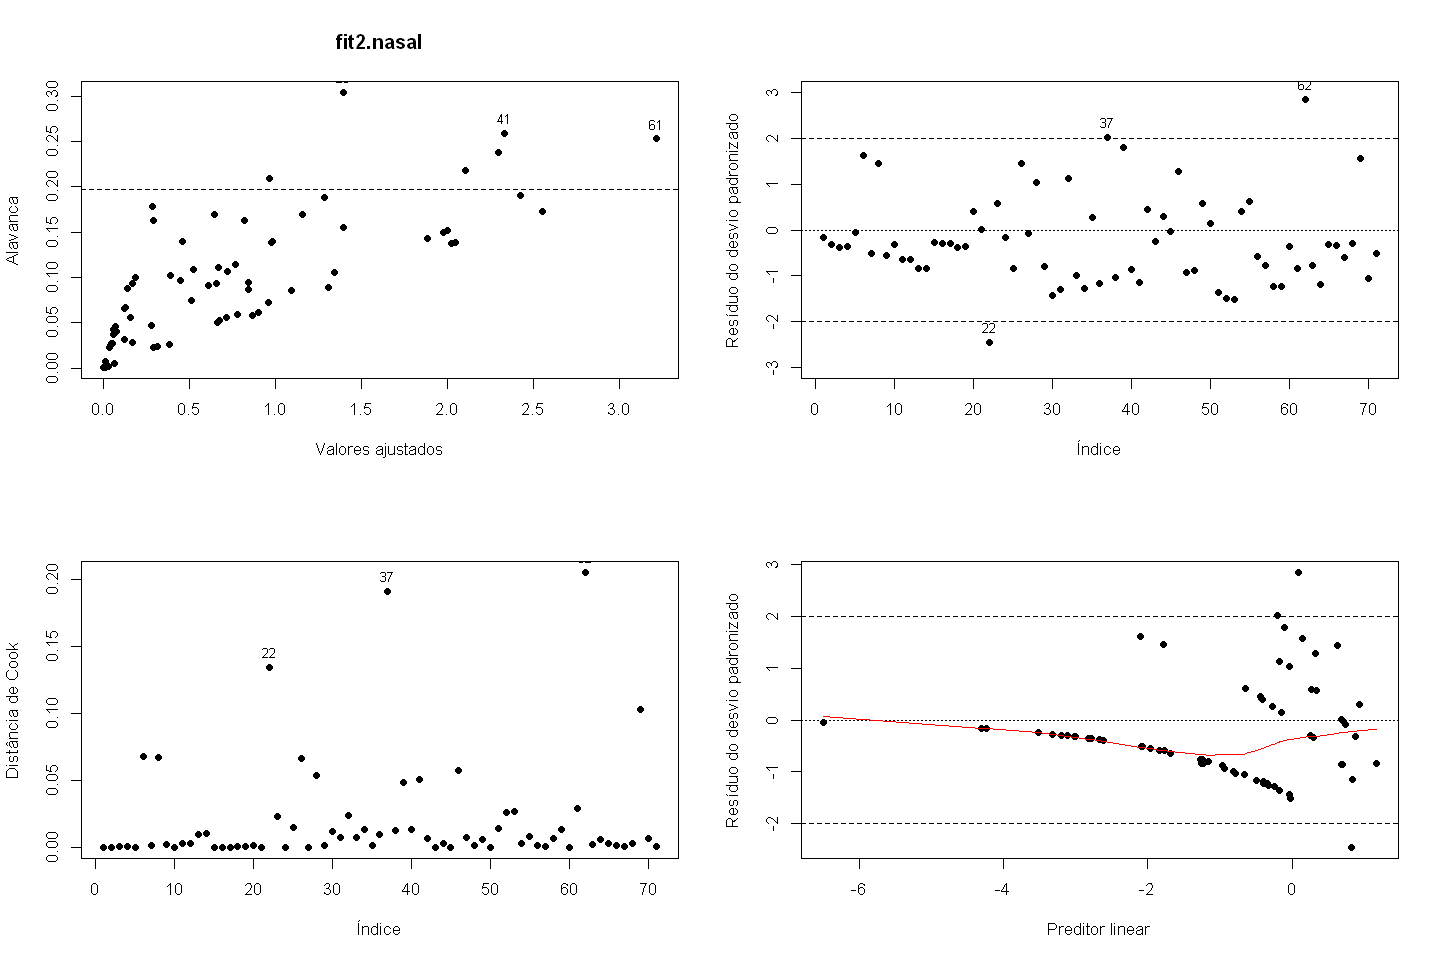

In [23]:
options(repr.plot.width = 12, repr.plot.height = 8) # deixar o gráfico grandinho

diag_glm(fit2.glm, titulo = "fit2.nasal")


- Alavanca: referência $2p/n = 14/71 \approx 0{,}20$. As observações 23, 41 e 61 ficam acima (≈ 0,24–0,30), sem valores muito afastados.
- Resíduos: destaca-se a obs. 62 ($t_D \approx 2{,}8$, que é da combinação idade 4, ano 2, tempo 3, com 5 casos em 56 pessoas-anos, muito mais que o esperado), e depois 22 e 37 (≈ 2,5 e 2,0).
- Cook: os maiores valores agora são **62 e 37** (≈ 0,21 e 0,19), seguidos da 22.
- Resíduo × preditor linear: sem padrão além daquilo de contagens de zero que comentamos antes.

Pontos fora do envelope: 0 de 71 (0.0%)


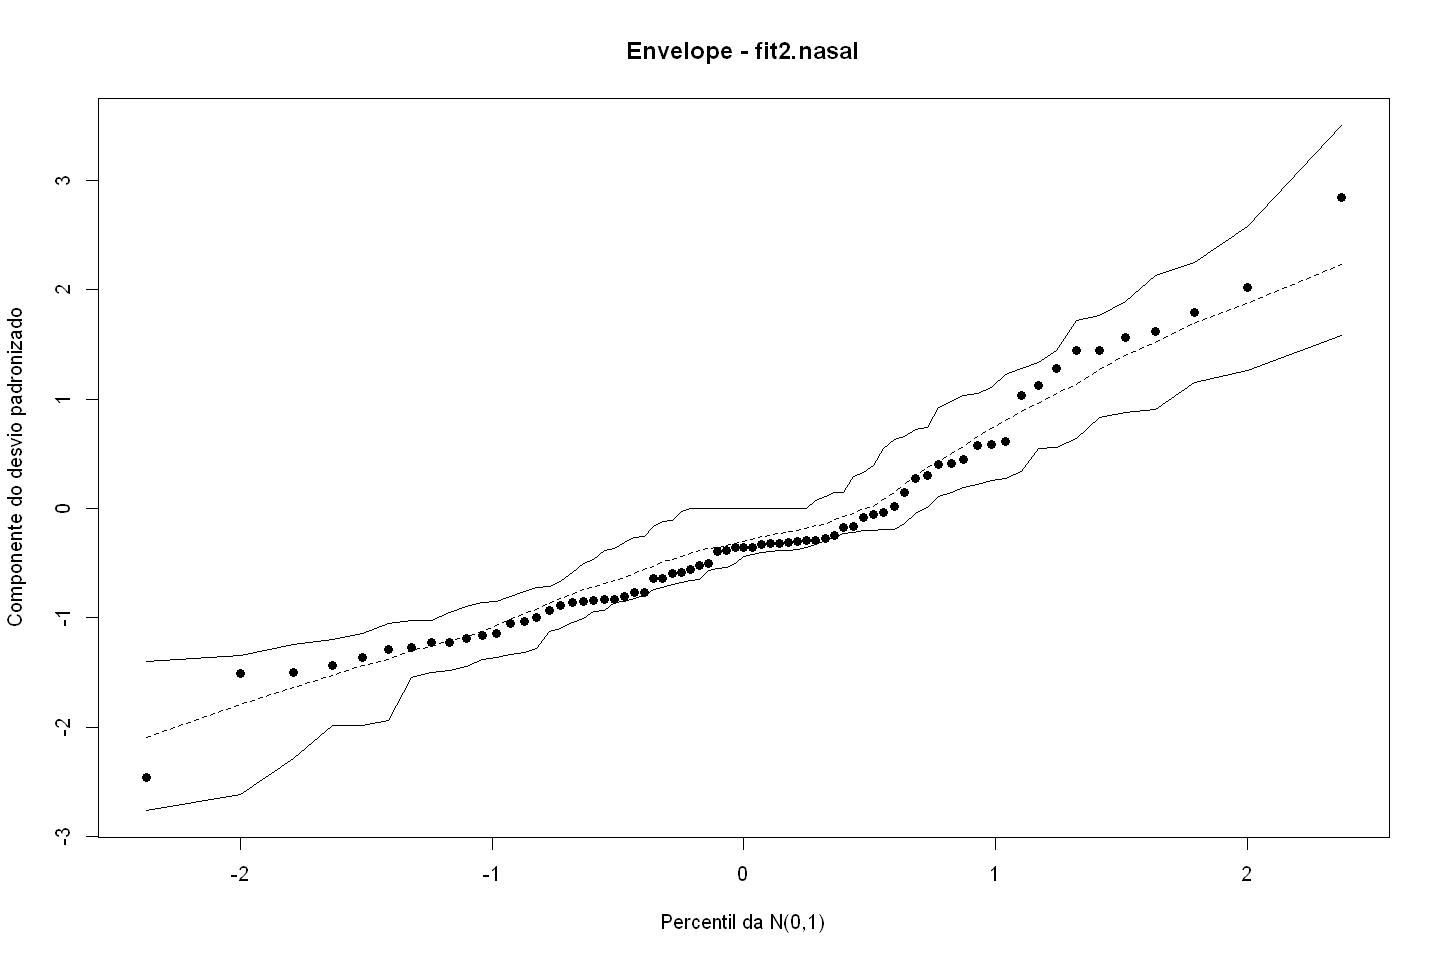

In [24]:
options(repr.plot.width = 12, repr.plot.height = 8) # deixar o gráfico grandinho

envelope_glm(fit2.glm, main = "Envelope - fit2.nasal")


Pontos dentro do enveplope. ótimo

### 1.5 sensiblidade com as observações especiais (aquelas se destacaram em diagnóstico)

In [25]:
for (k in c(62, 37, 22)) {
  ajk <- glm(casos ~ idade + nano + ntempo + offset(log(panos)), family = poisson, data = nasal, subset = -k)
  cat("\nSem a observação", k, "- variação % das estimativas e p-valores:\n")
  print(round(cbind(var_pct = (coef(ajk) - coef(fit2.glm)) / coef(fit2.glm) * 100,
                    p_valor = summary(ajk)$coefficients[, 4]), 3))
}


Sem a observação 62 - variação % das estimativas e p-valores:
              var_pct p_valor
(Intercept)     0.549   0.000
idade2         -0.196   0.023
idade3          0.016   0.001
idade4        -10.736   0.000
nano1920-1924  -7.561   0.000
ntempo40-49,9   7.937   0.028
ntempo50+       2.504   0.051

Sem a observação 37 - variação % das estimativas e p-valores:
              var_pct p_valor
(Intercept)    -1.264   0.000
idade2         -7.094   0.036
idade3          0.496   0.001
idade4         -0.349   0.000
nano1920-1924  18.802   0.000
ntempo40-49,9 -32.860   0.210
ntempo50+       1.978   0.052

Sem a observação 22 - variação % das estimativas e p-valores:
              var_pct p_valor
(Intercept)     0.623   0.000
idade2          8.220   0.014
idade3          0.017   0.001
idade4          1.089   0.000
nano1920-1924   2.636   0.000
ntempo40-49,9  27.684   0.008
ntempo50+      -4.389   0.067


Umas observações:
- sem 62: os parâmetros variam menos de 11%. as significâncias não mudaram
- sem 37: o efeito do `ntempo40-49,9` muda bastante (diminui uns 33%), e deixa de ser significativo. os outros mudam pouco.
- sem 22: o efeito do `ntempo-40-40,9` aumenta

deu pra ver que o efeito do `ntempo-40-40,9` é mais sensível a ponsto individduais. Nenhuma dessas obs parecem erro de registro, é melhor a gente manter todas elas.

### 1.6 term.plot e IC para razões de taxas


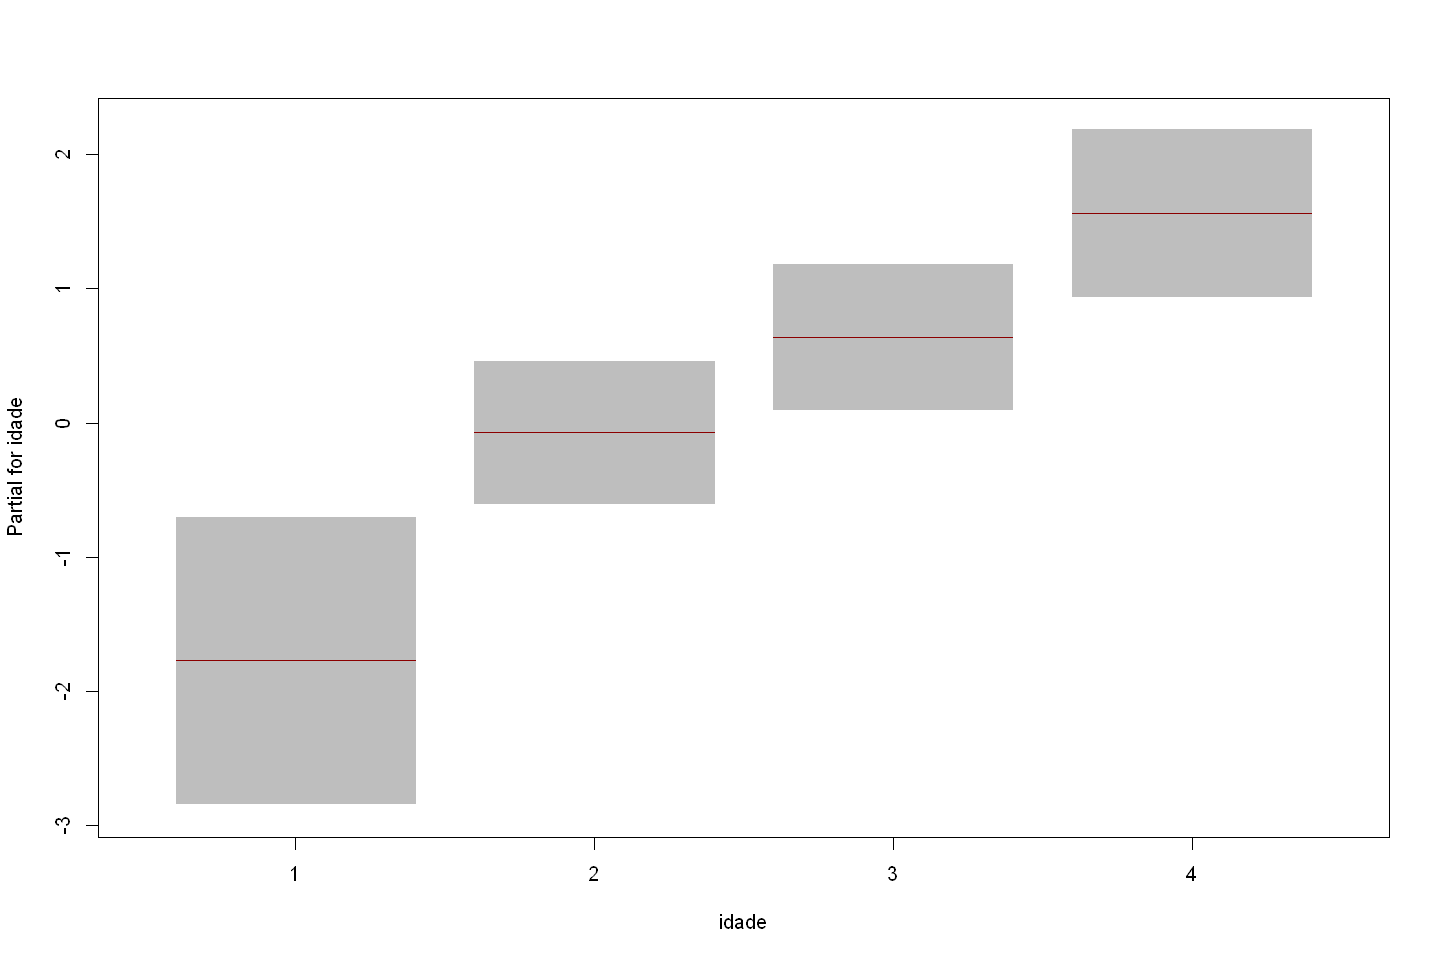

In [26]:
term.plot(fit2.gamlss, terms = 1)


Idade no primeiro emprego: o efeito parcial (escala log) cresce de forma monótona do nível 1 ao nível 4. As bandas são largas no nível 1 (poucos casos nessa faixa), mas o crescimento é claro: quanto mais velho o trabalhador entrou na refinaria, maior a taxa de câncer nasal.

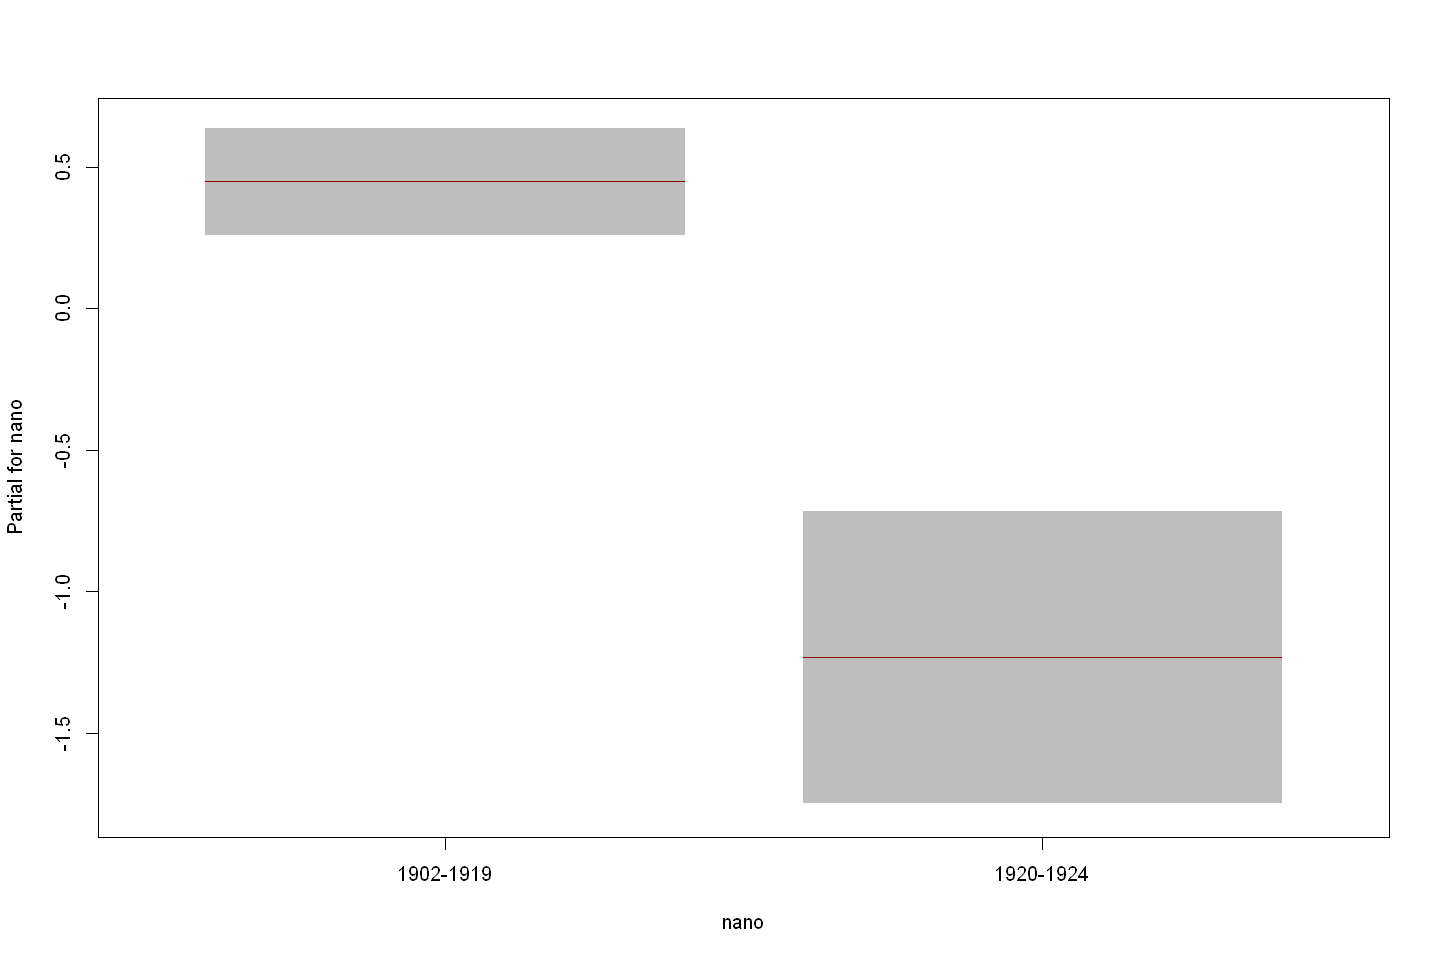

In [27]:
term.plot(fit2.gamlss, terms = 2)


Ano do primeiro emprego: quem entrou em 1920–1924 tem efeito bem menor do que quem entrou em 1902–1919. Isso é coerente com melhorias nas condições de trabalho/processo da refinaria a partir dos anos 1920.

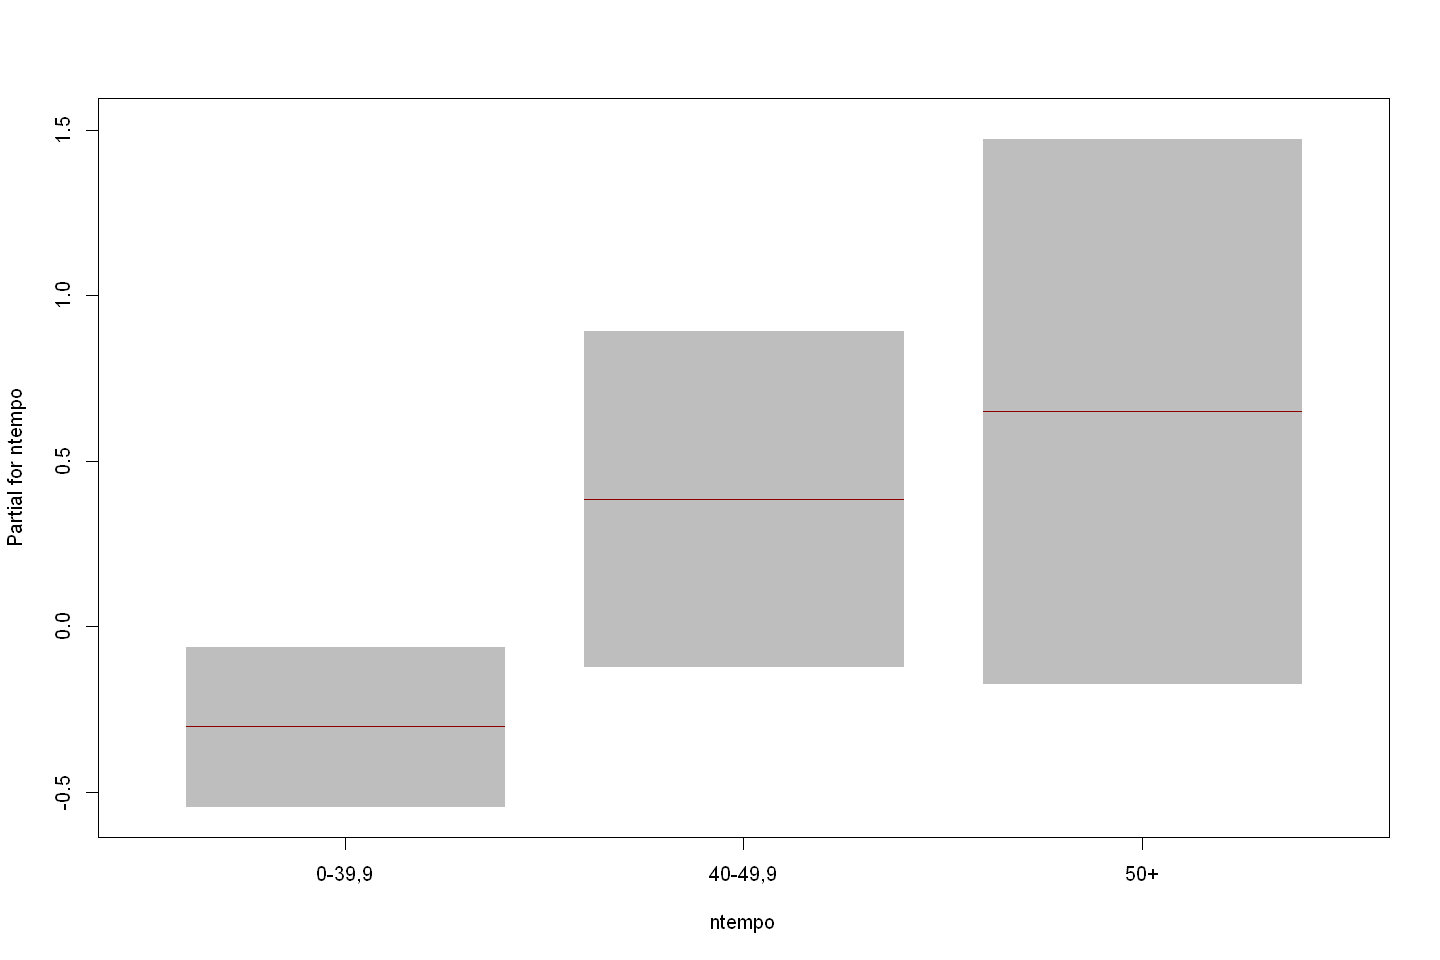

In [28]:
term.plot(fit2.gamlss, terms = 3)


Tempo desde o primeiro emprego: o efeito aumenta de "0–39,9" para "40–49,9" e "50+", refletindo o longo período de latência do câncer nasal. As bandas de "40–49,9" e "50+" se sobrepõem bastante.

In [29]:
# razões de taxas (exp dos coeficientes) e IC de 95% de Wald
est <- coef(fit2.gamlss)
ic  <- confint(fit2.gamlss)
round(exp(cbind(RT = est, ic))[-1, ], 3)

,RT,2.5 %,97.5 %
idade2,5.438,1.266,23.359
idade3,11.078,2.541,48.295
idade4,27.998,6.137,127.734
nano1920-1924,0.186,0.093,0.371
"ntempo40-49,9",1.991,1.033,3.837
ntempo50+,2.595,0.975,6.907


- idade: quem entrou no nível 4 de idade tem taxa estimada 28-1 = 27 vezes maior do que quem entrou no nível 1 (os ICs são largos porque o nível 1 tem só 2 casos).
- ano: quem entrou em 1920–1924 tem taxa aproximadamente 81% menor ($1 - 0{,}19$) que quem entrou em 1902–1919.
- tempo: com 40–49,9 anos desde o primeiro emprego a taxa é quase **o dobro** a de quem tem menos de 40 anos; com 50 anos ou mais, ≈ 2,6 vezes (IC inclui 1, marginalmente).

## Ex2

Faça ex22 do cap 5. dados de nitrofen.txt. é sobre 50 C.dubias. 5 níveis de nitrofen; cada nível tem 10 animais. A resposta é o total de ovos eclodidos após 3 nihadas. Faça: aded; compare ajustes; escolher o melhor ajuste; interpretar os coeficientes.

In [30]:
nit <- read.table(paste0(caminho, "L4-Q2-C5-EX22-nitrofen.txt"), header = TRUE)

str(nit)



'data.frame':	50 obs. of  2 variables:
 $ dose : int  0 0 0 0 0 0 0 0 0 0 ...
 $ tovos: int  37 32 34 33 36 34 33 30 24 31 ...


### 2.1 Aded

In [31]:
aggregate(tovos ~ dose, data = nit, FUN = function(x) c(media = mean(x = x), variancia = var(x = x)))

dose,tovos
<int>,"<dbl[,2]>"
0,"32.4, 13.155556"
80,"31.5, 10.722222"
160,"28.3, 5.566667"
235,"17.2, 34.844444"
310,"6.0, 13.777778"


Média por dose é: 32.4 (0mg/L); 31.5 (80mg/L); 28.3(160mg/L); 17.2(235mg/L); e 6 (310mg/L). A média cai um pounco até 160mg/L e depois despenca muito depois. As variâncias amostrais são 13.2; 10.7; 5.6; 34.8 e 13.8. Note que na doses baixas de herbicida, as variâncias ficam abaixo da média; e nas doses altas as variâncias ficam acima. parece ser um sinal de sobredispersão.

#### 2.1.1 gráfico de dispersão

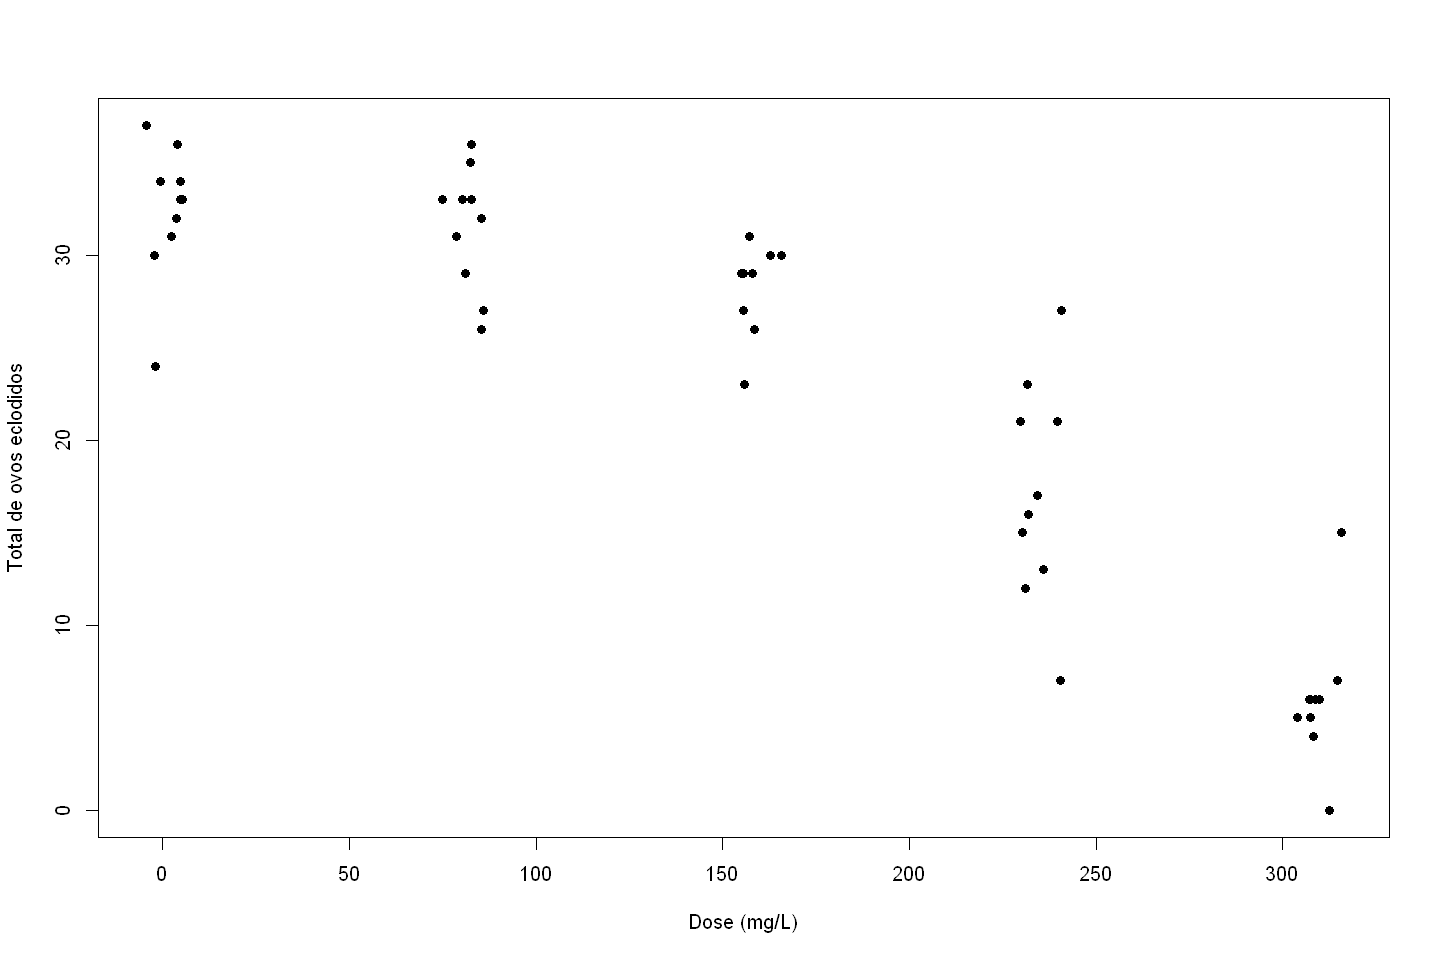

In [32]:
options(repr.plot.width = 12, repr.plot.height = 8) # deixar o gráfico grandinho

plot(jitter(nit$dose, 0.4), nit$tovos, xlab = "Dose (mg/L)", ylab = "Total de ovos eclodidos", pch = 16)

O gráfico de dispersão mostra uma relação não linear descrescente, e temos uma queda acentuada a partir de 235 mg/L de herbicida.

### 2.2 Comparando modelos poisson

vamos testar alguns:

- m1: ligação log e uma preditora
- m2: log e duas preditoras (dose e dose quadrado)
- m3: log e 3 preditoras (adicionando o termo cubico)
- m4: log e considerando dose como fator
- m5: identidade e uma preditora
- m6: raiz quad e + termo quadratico

Aliás descobrimos que na escala original da dose as funções do R não funciona muito bem. o R retorna que não é possível encontrar valores iniciais válidos.

In [33]:
nit$d <- nit$dose / 100

In [34]:
m1 <- glm(tovos ~ d, family = poisson, data = nit)
m2 <- glm(tovos ~ d + I(d^2), family = poisson, data = nit)
m3 <- glm(tovos ~ d + I(d^2) + I(d^3), family = poisson, data = nit)
m4 <- glm(tovos ~ factor(dose), family = poisson, data = nit)
m5 <- glm(tovos ~ d, family = poisson(link = "identity"), data = nit, start = c(35, -8))
m6 <- glm(tovos ~ d + I(d^2), family = poisson(link = "sqrt"), data = nit)
modelos <- list(M1 = m1, M2 = m2, M3 = m3, M4 = m4, M5 = m5, M6 = m6)
data.frame(ligacao = sapply(modelos, function(m) m$family$link),
           qtd_pred = sapply(modelos, function(m) length(coef(m))),
           desvio = round(sapply(modelos, deviance), 2),
           gl = sapply(modelos, df.residual),
           AIC = round(sapply(modelos, AIC), 2))

,ligacao,qtd_pred,desvio,gl,AIC
,<chr>,<int>,<dbl>,<int>,<dbl>
M1,log,2,123.93,48,365.33
M2,log,3,56.61,47,300.02
M3,log,4,50.77,46,296.18
M4,log,5,50.70,45,298.11
M5,identity,2,81.14,48,322.55
M6,sqrt,3,52.03,47,295.44


na saída acima podemos ver que:

- m1: meio ruim; desvio de 123.93, e AIC de 365.33
- m5: meio ruim, igual m1, desvio alto e AIC alto
- m2: melhorou; desvio de 56.61 e AIC de 300
- os m3 e m4 m6 têm AIC um pouco menores.

Vamos fazer anova para comparar modelos. (teste entre os encaixados)

In [35]:
anova(m1, m2, m3, test = "Chisq")
anova(m2, m4, test = "Chisq")

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,48,123.92908,NA,NA,NA
2,47,56.60992,1,67.319154,2.309270e-16
3,46,50.77449,1,5.835431,1.570656e-02


,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,47,56.60992,NA,NA,NA
2,45,50.70027,2,5.909656,0.05208763


observações:
- parece que o termo quadrático é estatísticamente significativo ao nível de 5% (valor-p de 2e-16)
- o termo cúbido tambbém significativo a 5%
- mas no modelo usando dose como fator a significância do termo quadrático foi rejeitada ao nivel de 5%.

Ademais vimos que o desvio de m2 dá 56.6 com 47g.l, cuja dá proximo de 1.2; e o de m4 dá 50.7 com 45 g.l. Esses valores indicam que não temos uma sobredispersão muito relevante. Logo vamos dizer que a Poisson é adequado sim nessa situação. A proxima parte é o diagnostico.

#### envelopes

Pontos fora do envelope: 38 de 50 (76.0%)
Pontos fora do envelope: 3 de 50 (6.0%)
Pontos fora do envelope: 5 de 50 (10.0%)
Pontos fora do envelope: 8 de 50 (16.0%)
Pontos fora do envelope: 6 de 50 (12.0%)
Pontos fora do envelope: 3 de 50 (6.0%)


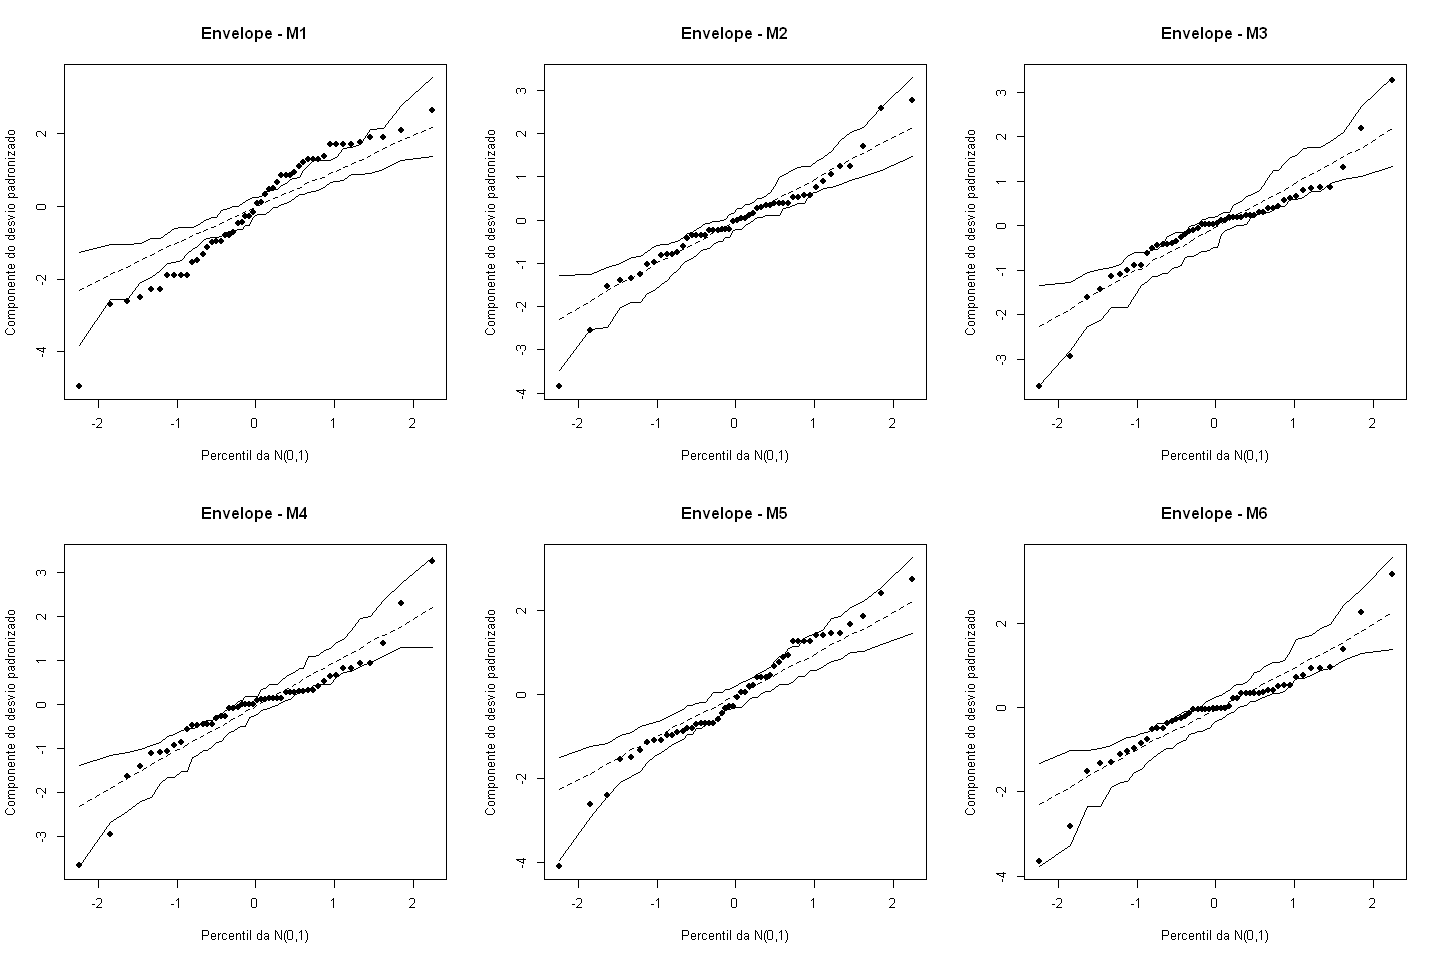

In [36]:
options(repr.plot.width = 12, repr.plot.height = 8)
# usando a função que fizemos para gerar envelopes

par(mfrow = c(2, 3))
for (nm in names(modelos)) envelope_glm(modelos[[nm]], main = paste("Envelope -", nm))
par(mfrow = c(1, 1))

Pontos fora do envelope para cada modelo: 

- m1: 38 (tá mal ajustado. muitos pontos fora)
- m2: 3 (ok, só pontos nas caudas que estão fora)
- m3: 5 (o termo cúbico não melhorou em envelope)
- m4: 8 (meio ruim comparando com m2)
- m5: 6 (meio ruim também, e AIC pior que m2)
- m6: 3 (ok, só pontos nas caudas que estão fora)


Vamos escolhero m2 como o nosso modelo final: Poisson + ligação log + termo quadratico da dose. Pois tem AIC bom, envelope bom e interpretação simples.

### 2.3 diagnostico do modelo final

Referência 2p/n = 0.12 


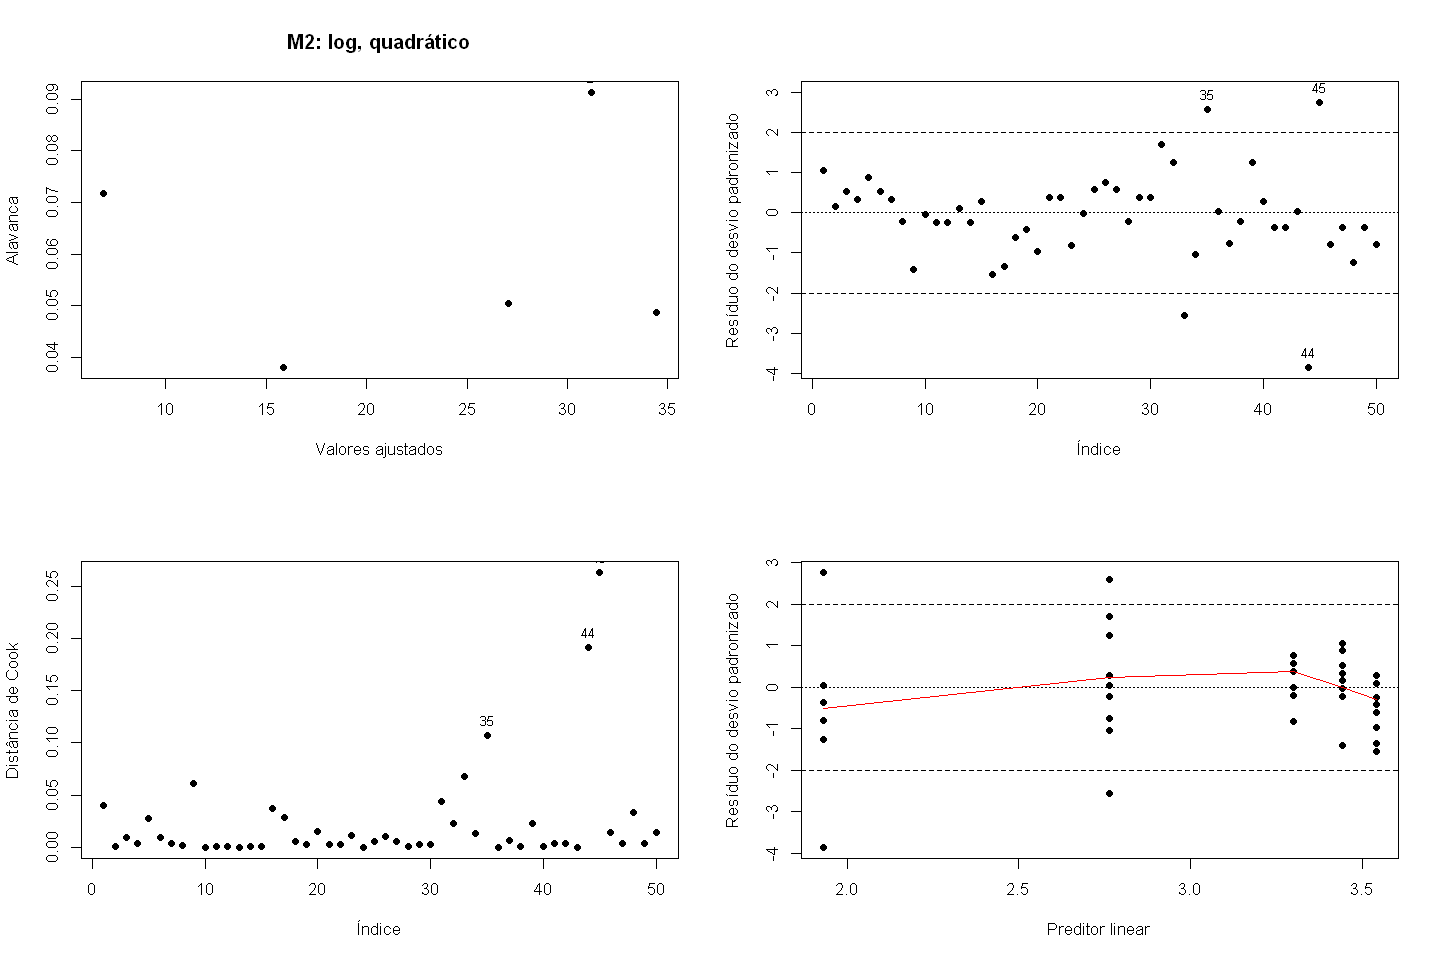

In [37]:
options(repr.plot.width = 12, repr.plot.height = 8)

dm2 <- diag_glm(m2, titulo = "M2: log, quadrático")


In [38]:
head(sort(cooks.distance(m2), decreasing = TRUE))

45         44         35         33          9         31 
0.26291719 0.19138392 0.10708897 0.06789261 0.06075141 0.04396704

comentários:
- alavanca: não parece ter algo incomun. pontos baixo da reta de referência 2p/n = 6/60 = 0.12.
- resíduos: alguns pontos notáveis: 45, 44 e 45, são os animais com mais ou menos ovos do que o modelo espera para a dose recebida.
- cook: 45 e 44 se destacam.
- resíduo vs preditor linear: um funil que encolhe com aumento da dose. indicativo de heterocedasticidade/superdispersão ness caso.


#### Verificando sensiblidade.

vamos ver se as obs 45 e 44 afetam no modelo

In [39]:
for (k in c(44, 45)) {
  ajk <- glm(tovos ~ d + I(d^2), family = poisson, data = nit, subset = -k)
  cat("\nSem a observação", k, "- variação % das estimativas e p-valores:\n")
  print(round(cbind(var_pct = (coef(ajk) - coef(m2)) / coef(m2) * 100,
                    p_valor = summary(ajk)$coefficients[, 4]), 4))
}
nit[c(44, 45), ]


Sem a observação 44 - variação % das estimativas e p-valores:
             var_pct p_valor
(Intercept)   0.1604  0.0000
d           -10.0133  0.0013
I(d^2)       -6.8158  0.0000

Sem a observação 45 - variação % das estimativas e p-valores:
            var_pct p_valor
(Intercept) -0.1997   0e+00
d           12.4033   1e-04
I(d^2)       8.4747   0e+00


,dose,tovos,d
,<int>,<int>,<dbl>
44,310,0,3.1
45,310,15,3.1


Com a saída acima vimos que a obs44 (0 ovos) e a 45 (15 ovos, que é muito maior que o 6 que é a média da dose 310mg/L) puxam os coeficientes no sentidos opostos (uma tem variação negativa e outra positiva). mas a retirada de qualquer uma delas muda pouco a forma e os coeficientes não perdem significância. Vamos dizer que são valores plausíveis e manter todas elas.

### 2.4 interpretando

In [40]:
summary(m2)
exp(coef(m2))
dose_pico <- -coef(m2)[2] / (2 * coef(m2)[3]) * 100
cat("Dose em que a média estimada é máxima:", round(dose_pico, 1), "mg/l\n")


Call:
glm(formula = tovos ~ d + I(d^2), family = poisson, data = nit)

Coefficients:
            Estimate Std. Error z value Pr(>|z|)    
(Intercept)  3.43947    0.05411  63.570  < 2e-16 ***
d            0.33552    0.09385   3.575  0.00035 ***
I(d^2)      -0.26506    0.03334  -7.950 1.87e-15 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for poisson family taken to be 1)

    Null deviance: 319.02  on 49  degrees of freedom
Residual deviance:  56.61  on 47  degrees of freedom
AIC: 300.02

Number of Fisher Scoring iterations: 4


(Intercept)           d      I(d^2) 
 31.1704440   1.3986611   0.7671618

Dose em que a média estimada é máxima: 63.3 mg/l


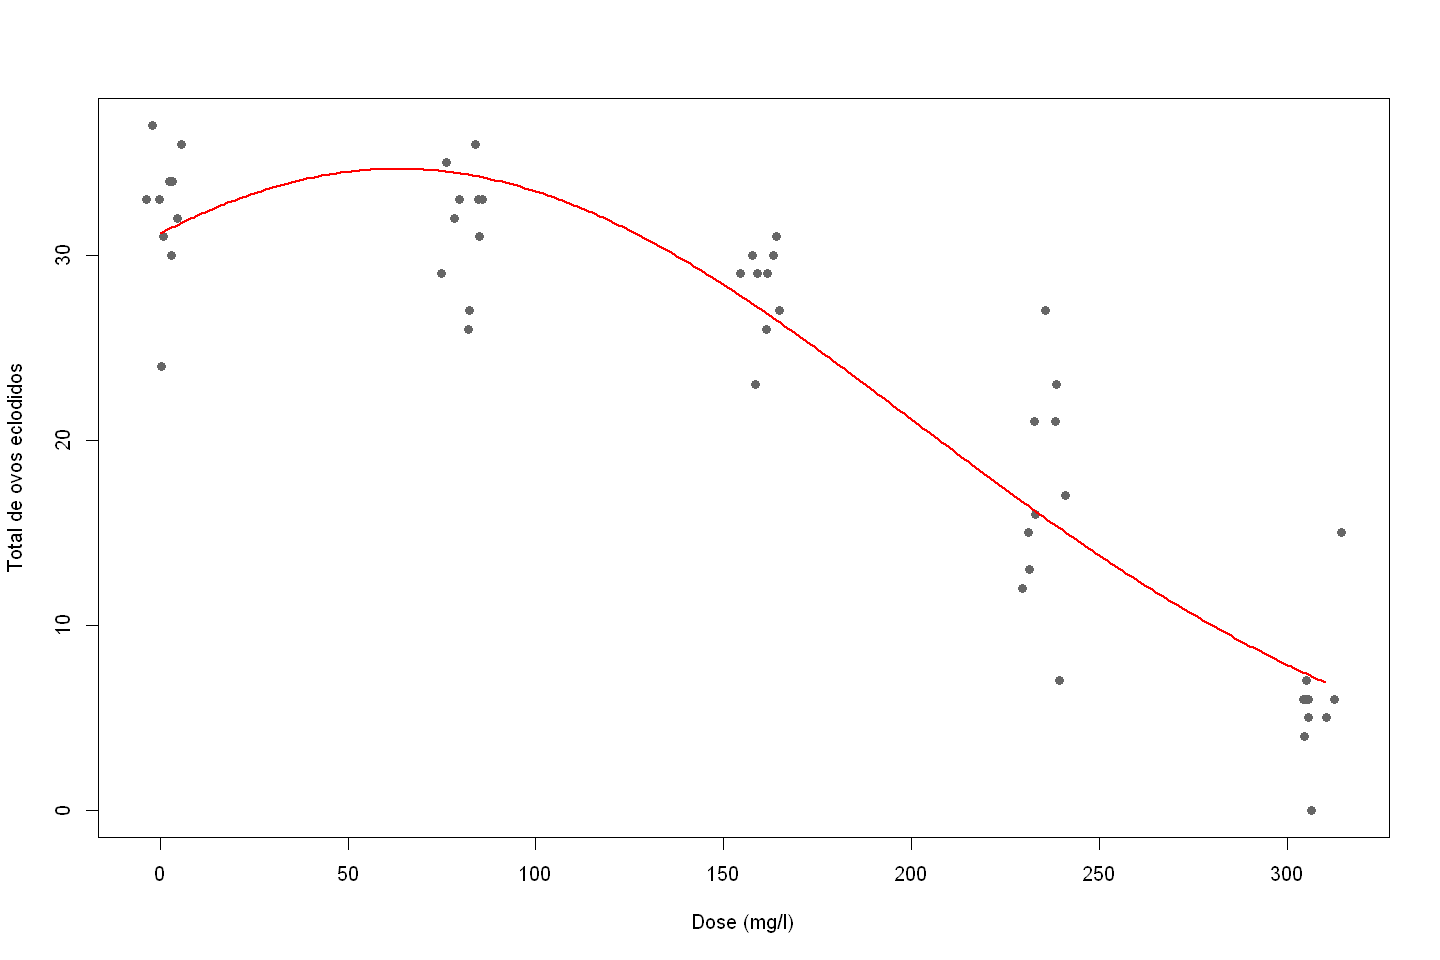

In [41]:
options(repr.plot.width = 12, repr.plot.height = 8)

# curva ajustada sobre os dados
plot(jitter(nit$dose, 0.4), nit$tovos, xlab = "Dose (mg/l)", ylab = "Total de ovos eclodidos", pch = 16, col = "grey40")
dd <- seq(0, 310, 1)
lines(dd, predict(m2, newdata = data.frame(d = dd / 100), type = "response"), col = "red", lwd = 2)

relembrando que nós usamo d que é dose/100 para ajustar a escala com a função do R.

o modelo ajustado é:
$$\log \hat\mu(d) = 3{.}439 + 0{.}336\,d - 0{.}265\,d^2, \qquad \text{onde} \qquad d = \text{dose}/100.$$


- intercepto: 3.439 é a media estimada sem herbicida
- como temos termo quadrático, o efeito da dose não fica constante.
- sobre a curva ajustada, temos uma parabola cuja maximo tá em $d = -\beta_1/(2\beta_2) \approx 0{,}63$, que dá uns 63mg/L de herbicida. Então doses baixas não prejudicam a eclosão, mas a aprtir desse 63mg/L o número médiode ovos cai.

## Ex3

Faça ex 7 do cap5. não precisa o modelo de quase verosiimilhanlça.

rolos.txt; temos 32 peças de tecido. comprimento da peça (m) e npumero de falhas.  
iniciamente: gráfico de num_faalhas vs comprimento_peça. ajuste um log-linear de poisson. análise de respíduos. ver se tem sobredispersão. interprete pelas razões de médias.

### 3.1 Aded

In [42]:
rolos <- read.table(paste0(caminho, "L4-Q3-C5-EX7-rolos.txt"), header = TRUE)
str(rolos)
summary(rolos)
c(media_falhas = mean(rolos$falhas), var_falhas = var(rolos$falhas))

'data.frame':	32 obs. of  2 variables:
 $ comprimento: int  551 543 651 842 832 905 375 542 715 522 ...
 $ falhas     : int  6 8 4 9 17 23 9 9 14 6 ...


  comprimento        falhas      
 Min.   :122.0   Min.   : 1.000  
 1st Qu.:453.8   1st Qu.: 5.750  
 Median :590.5   Median : 8.000  
 Mean   :587.7   Mean   : 8.875  
 3rd Qu.:735.8   3rd Qu.: 9.250  
 Max.   :952.0   Max.   :28.000  

media_falhas   var_falhas 
     8.87500     33.79032

Deu pra ver que os comprimentos variam de 122 a 952; a variacnia amostral de falhas é 33.8 que é bem maior que a média amostral de 8.9; parece que vamos ter que avaliar a sobredispersão no modelo.


#### gráfico de dispersão (na escala original e na log):

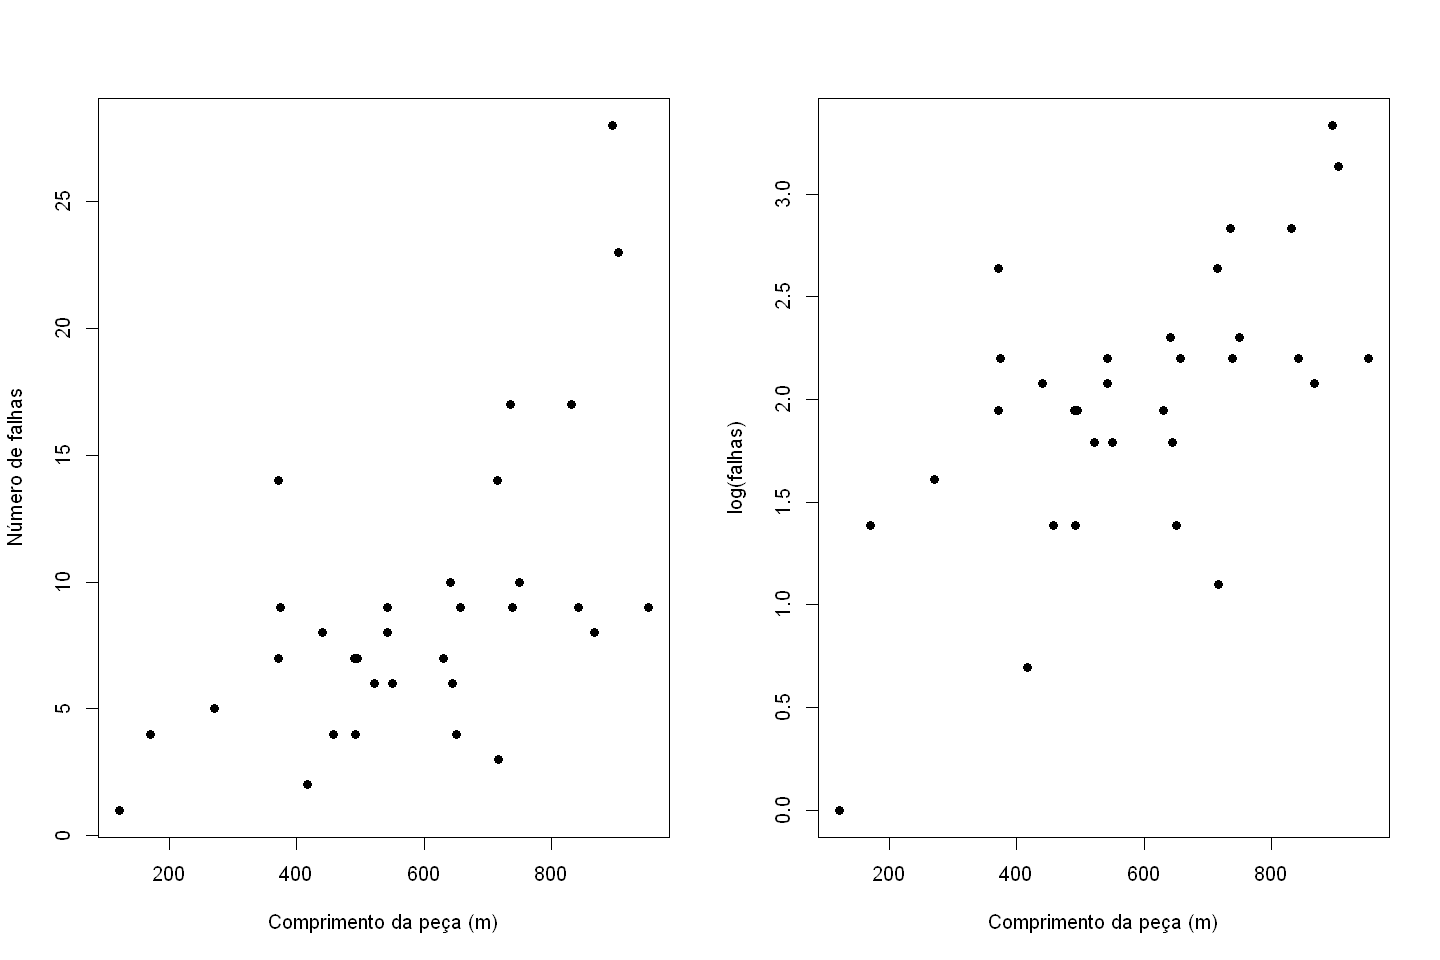

In [43]:
options(repr.plot.width = 12, repr.plot.height = 8)

par(mfrow = c(1, 2))
plot(rolos$comprimento, rolos$falhas, xlab = "Comprimento da peça (m)", ylab = "Número de falhas", pch = 16)
plot(rolos$comprimento, log(rolos$falhas), xlab = "Comprimento da peça (m)", ylab = "log(falhas)", pch = 16)
par(mfrow = c(1, 1))

Essa tendência nos gráficos quer dizer que o número de falahas aumenta com o comprimento da peça. além disso dá pra ver que a variabilidade aumenta junto com o comprimento na escala original. Na escala log o comportamento parece mais linear. Isso sugere que o log pode ser a ligação recomendada.

### 3.2 Modelo com ligação log e poisson

In [44]:
fit.p <- glm(falhas ~ comprimento, family = poisson(link="log"), data = rolos)
summary(fit.p)


Call:
glm(formula = falhas ~ comprimento, family = poisson(link = "log"), 
    data = rolos)

Coefficients:
             Estimate Std. Error z value Pr(>|z|)    
(Intercept) 0.9717506  0.2124693   4.574 4.79e-06 ***
comprimento 0.0019297  0.0003063   6.300 2.97e-10 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for poisson family taken to be 1)

    Null deviance: 103.714  on 31  degrees of freedom
Residual deviance:  61.758  on 30  degrees of freedom
AIC: 189.06

Number of Fisher Scoring iterations: 4


Temos que $\log\hat\mu = 0{,}972 + 0{,}00193\,x$, com comprimento muito significativo (valor-p muito baixo, proximo de 3e-06)

In [45]:
c(desvio = deviance(fit.p), gl = df.residual(fit.p),
  desvio_gl = deviance(fit.p) / df.residual(fit.p),
  pearson_gl = sum(residuals(fit.p, type = "pearson")^2) / df.residual(fit.p),
  p_valor = 1 - pchisq(deviance(fit.p), df.residual(fit.p)))

desvio           gl    desvio_gl   pearson_gl      p_valor 
6.175774e+01 3.000000e+01 2.058591e+00 2.121933e+00 5.610935e-04

Temos desvio = 61.8 com 30 gl, D/gl = 61.8/40 dá proximo de 2.06; A variabilidade tá mais que o dobro que a poisson admite. indício de sobredispersão.

#### diagnostico

Referência 2p/n = 0.125 


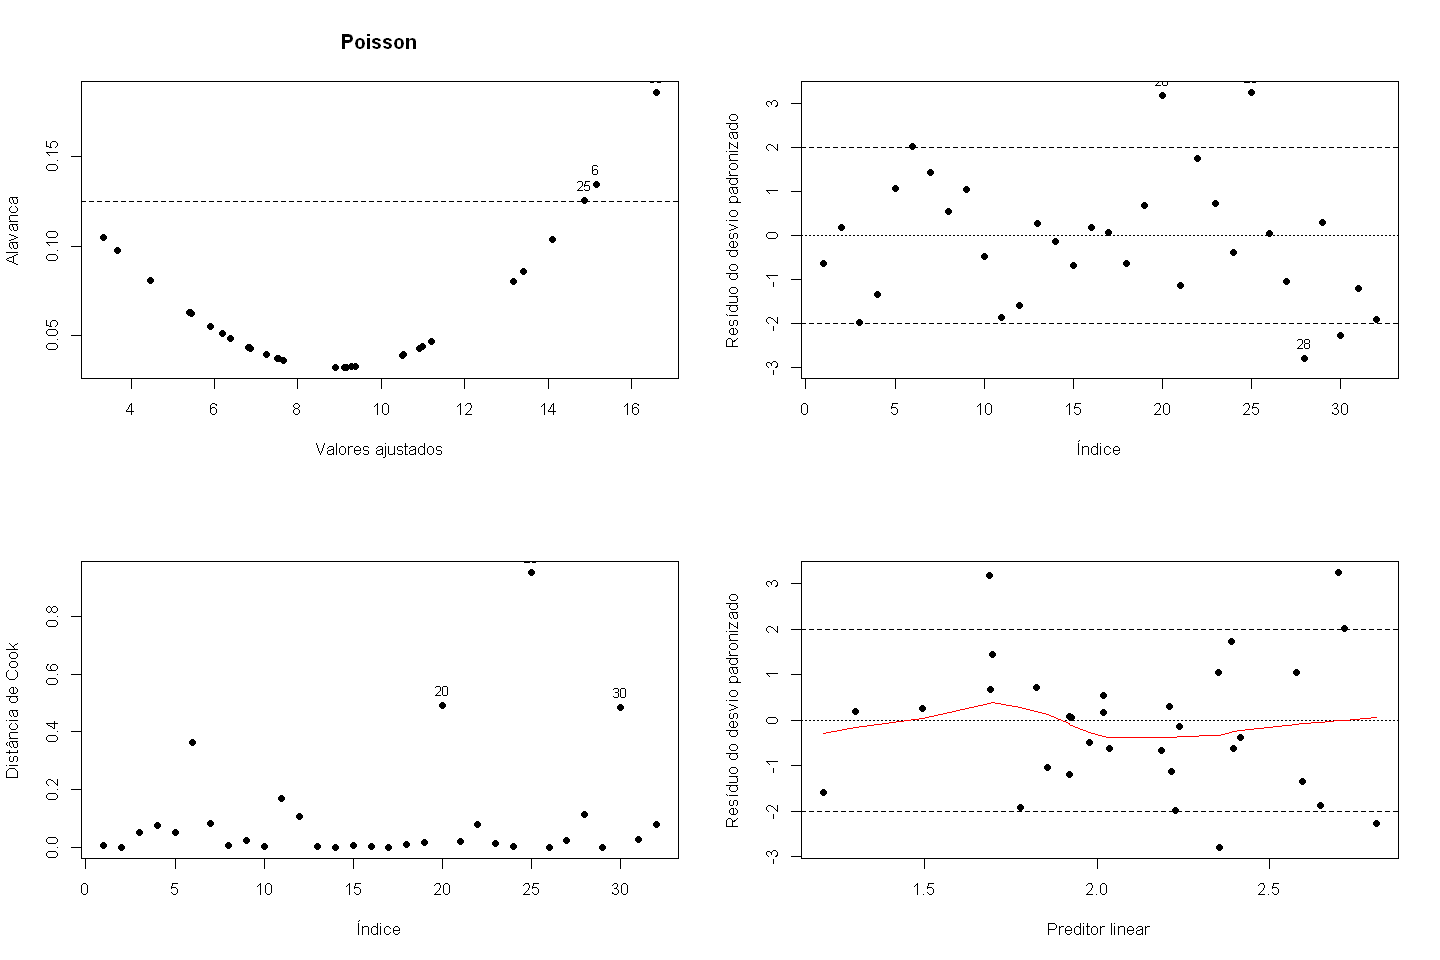

In [46]:
dp <- diag_glm(fit.p, titulo = "Poisson")

In [47]:
head(sort(hatvalues(fit.p),decreasing = TRUE))

30          6         25         12         11         16 
0.18567303 0.13450630 0.12541177 0.10464483 0.10364705 0.09761694

In [48]:
head(sort(rstandard(fit.p),decreasing = TRUE))


25       20        6       22        7        5 
3.242012 3.176484 2.011536 1.739500 1.434972 1.055287

In [49]:
head(sort(cooks.distance(fit.p),decreasing = TRUE))


25        20        30         6        11        28 
0.9518937 0.4917913 0.4862502 0.3648807 0.1705872 0.1151422

- alavanca: uns pontos acima da reta de referência. as obs 30 e 6 são as que apresentam maiores h_ii.
- resíduos: uns pontos fora do -2 a 2. As obs que se destacam mais são: 25; 20 e 6. temos n =32, era pra ter menos pontos fora do intervalo.
- cook: a obs 25 se destaca, tá alta.

Pontos fora do envelope: 3 de 32 (9.4%)


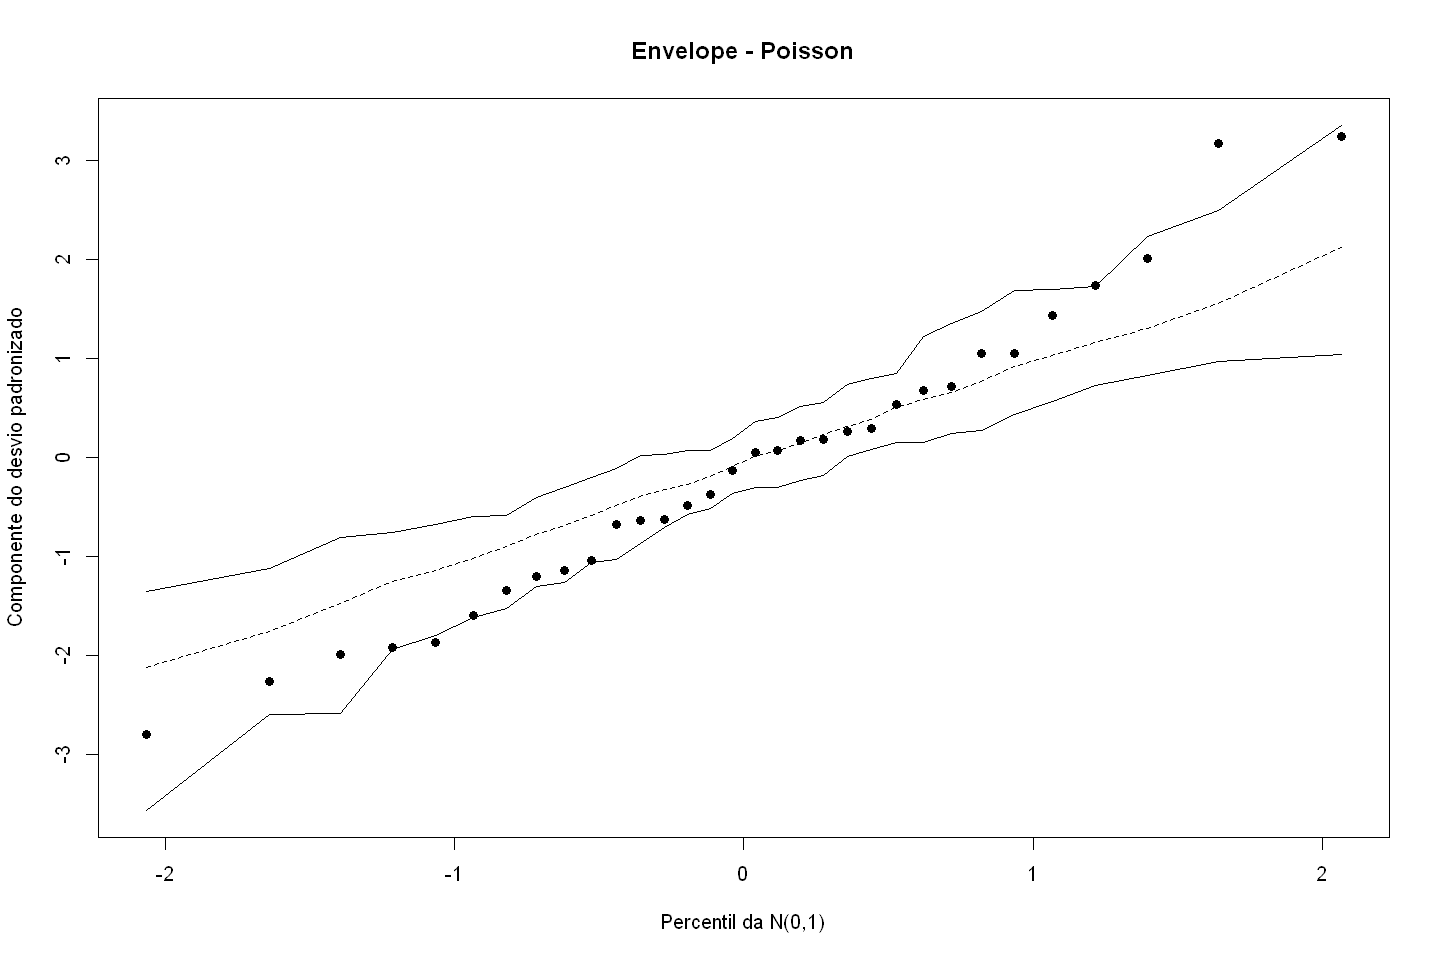

In [50]:
envelope_glm(fit.p, main = "Envelope - Poisson")


Tem 3 pontos fora do envelope. Isso dá 3/32 que é uns 9% dos pontos fora do envelope, e o como padrão dos resíduos tá mais espalhados que a gente espera, temos sinais de sobredispersão. Junto com o D/gl que é proximo de 2, vamos dizer que o modelo de poisson não é adequado. Vamos para o binominal negativa que o enunciado sugere.

### 3.3 Binomial negativa

ajustando o modelo com dist bin. negativa e ligação log. 

In [51]:
fit.bn <- glm.nb(falhas ~ comprimento, data = rolos)
summary(fit.bn)
c(AIC_Poisson = AIC(fit.p), AIC_BN = AIC(fit.bn))


Call:
glm.nb(formula = falhas ~ comprimento, data = rolos, init.theta = 9.56973877, 
    link = log)

Coefficients:
             Estimate Std. Error z value Pr(>|z|)    
(Intercept) 1.0014663  0.2783655   3.598 0.000321 ***
comprimento 0.0018827  0.0004214   4.468  7.9e-06 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for Negative Binomial(9.5697) family taken to be 1)

    Null deviance: 52.732  on 31  degrees of freedom
Residual deviance: 31.307  on 30  degrees of freedom
AIC: 180.55

Number of Fisher Scoring iterations: 1


              Theta:  9.57 
          Std. Err.:  4.89 

 2 x log-likelihood:  -174.554 

AIC_Poisson      AIC_BN 
   189.0559    180.5537

- o modelo fica assim: $\log\hat\mu = 1{,}001 + 0{,}00188\,x$; as estimativas dos coeficientes não mudaram muito em relação aopoisson, maso erro padrão aumentou.
- Desvio = 31.3, gl= 30. (razão dá proximo de 1, indicio de que não temos problema de sobredispersão)
- AIC caiu de 189 para 180 quando mudamos de poisson para binomial negativa. a gente rejeitaria o modelo poisson se for fazer um TRV

#### diagnóstico

Referência 2p/n = 0.125 


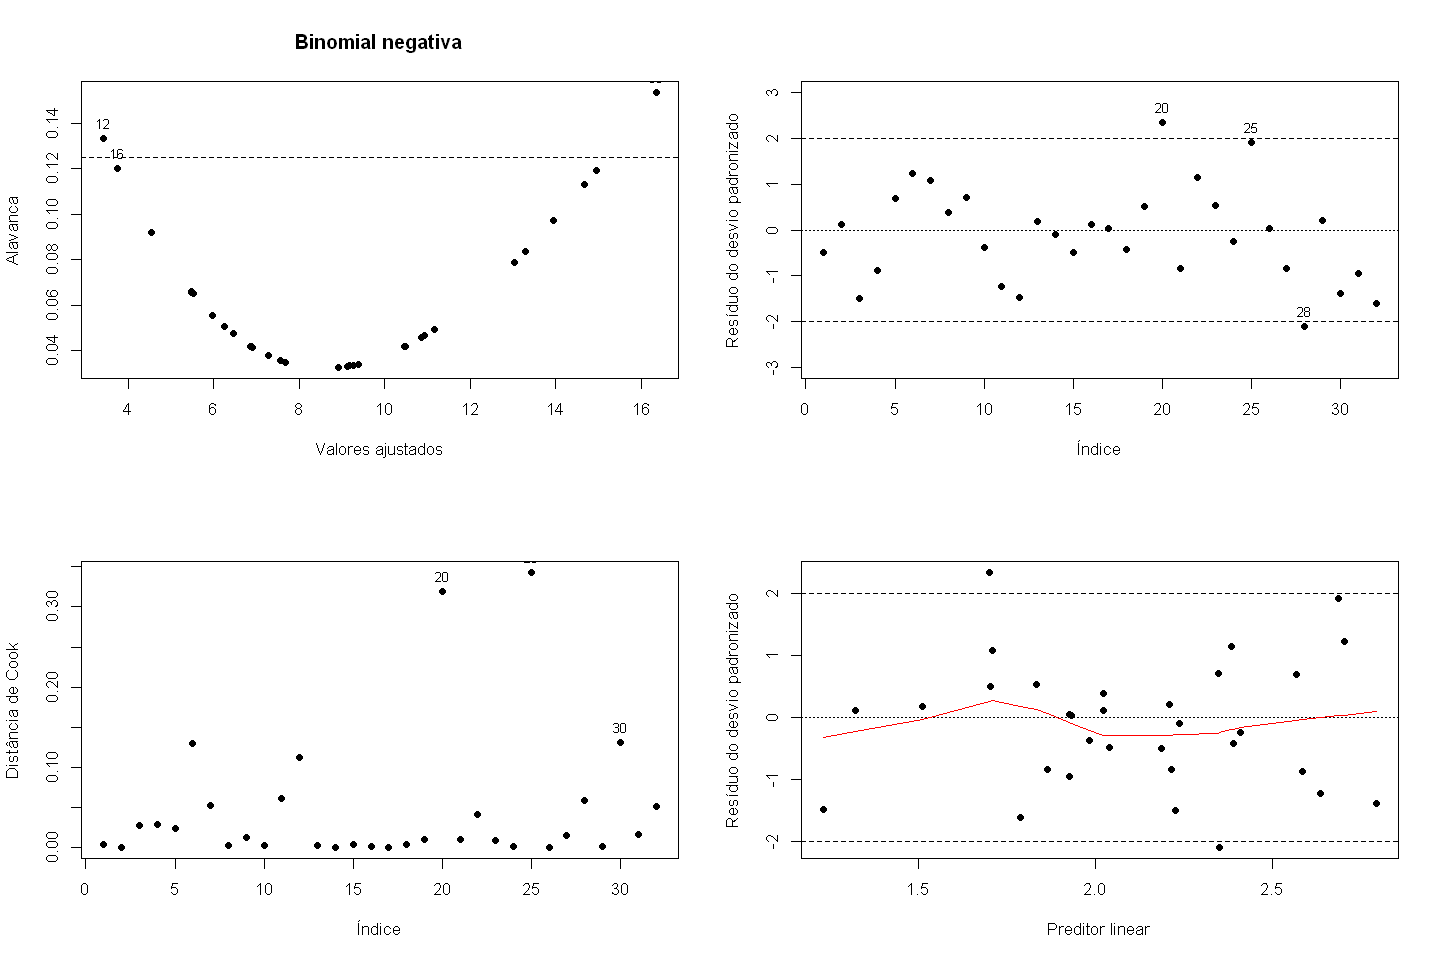

In [52]:
dnb <- diag_glm(fit.bn, titulo = "Binomial negativa")


In [53]:
head(sort(hatvalues(fit.bn),decreasing = TRUE))

30         12         16          6         25         11 
0.15366422 0.13328342 0.12012158 0.11950052 0.11306417 0.09709042

In [54]:
head(sort(abs(rstandard(fit.bn)),decreasing = TRUE))


20       28       25       32        3       12 
2.343151 2.101851 1.918567 1.610860 1.502892 1.482291

In [55]:
head(sort(cooks.distance(fit.bn),decreasing = TRUE))


25         20         30          6         12         11 
0.34276011 0.31931038 0.13069429 0.12996613 0.11218227 0.06151982

- alavanca: igual poisson, as obs 30 e 6 estão um pouco acima.
- resíduos: menos pontos fora do intervalo de -2 a 2. só as obs 20 e 28 estão grande. 2 pontos fora é esperado com n = 32
- cook: os maiores são 25 e 20, mas suas distancias são menores comparando com a maior em poisson (0.95)

Pontos fora do envelope: 0 de 32 (0.0%)


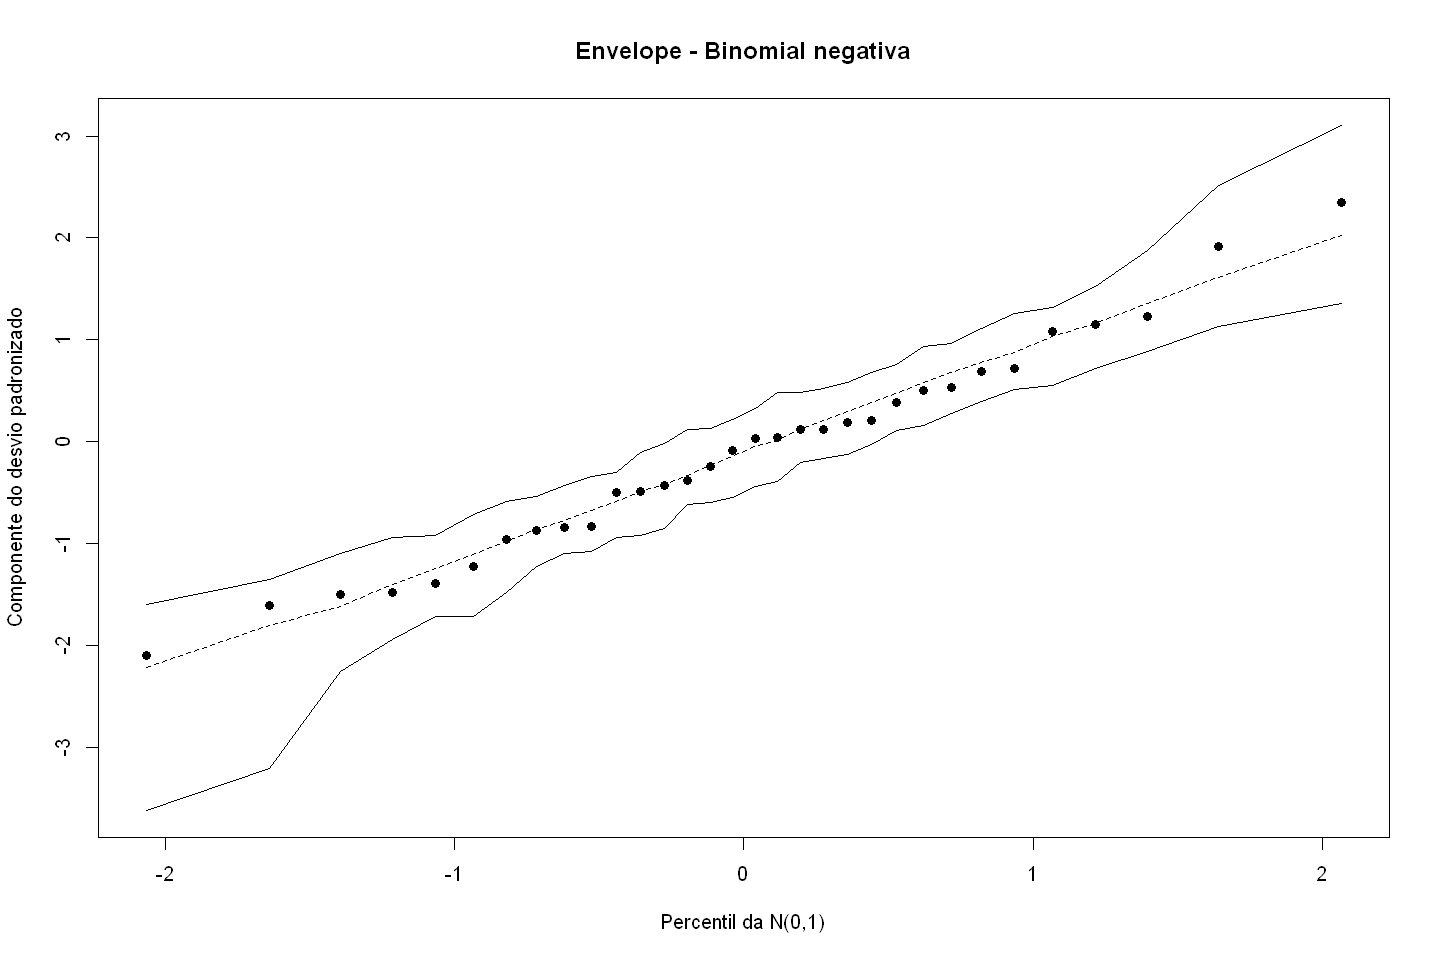

In [56]:
envelope_glm(fit.bn, main = "Envelope - Binomial negativa")


Todos os pontos dentro do envelope, ótimo. modelo bem ajustado.

### 3.4 Interpretação da razão de médias. $\mu(x+1)/\mu(x)$

In [57]:
rm <- rbind(BN      = c(coef(fit.bn)[2], confint.default(fit.bn)[2, ]))
colnames(rm) <- c("exp(beta1)", "2,5%", "97,5%")

In [58]:
list(por_metro = round(exp(rm), 5), por_100m = round(exp(100 * rm), 3))

,exp(beta1),"2,5%","97,5%"
BN,1.00188,1.00106,1.00271
,exp(beta1),"2,5%","97,5%"
BN,1.207,1.111,1.311


uh Com função de ligação log temos que $\mu(x+1)/\mu(x)$ dá o próprio $e^{\beta_1}$
- com modelo BN temos que a estimativa de $e^{\beta_1}$ é 1.0019, ou seja estima-se que cada metro a mais aumenta o número médio de falhas em aproximadamente 0.19%. Podemos ver isso na escala de 100m: $\mu(x+100)/\mu(x) = e^{100\beta_1}$, que dá uns 1.207, ou seja, estima-se que cada 100 m a mais na peça aumenta o número médio de falhas em aproximadamente 21%.


## EX 4 

Faça ex 10 do cap 4.

Experimento para avaliar a germinação de um determinado tipo de semente. Sob três codições: níveis de temp (21,42,62 ºC); níveis de umidade (baixo, médio, alto); nível de temp de germinação (11 e 21 ºC).

### 4.1 Aded

In [59]:
sementes <- read.table(paste0(caminho, "L4-Q4-C4-EX10-sementes.txt"), header = TRUE)
sementes$tempg   <- factor(sementes$tempg)
sementes$umidade <- factor(sementes$umidade, levels = c("baixo", "medio", "alto"))
sementes$temp    <- factor(sementes$temp)
sementes$m <- 100
sementes



tempg,umidade,temp,nsg,m
<fct>,<fct>,<fct>,<int>,<dbl>
11,baixo,21,98,100
11,baixo,42,96,100
11,baixo,62,62,100
11,medio,21,94,100
11,medio,42,79,100
11,medio,62,3,100
11,alto,21,92,100
11,alto,42,41,100
11,alto,62,1,100


Temos 18 combinações (2 x 3 x 3 = 18), cada combinação tem 100 sementes. Vamos usar os níveis mais baixos como as referências: ref de `umidade` é "baixo", ref de `tempg`  é "21", ref de `temp`  é "11".


In [60]:
xtabs(nsg ~umidade + temp + tempg, data = sementes)

, , tempg = 11

       temp
umidade 21 42 62
  baixo 98 96 62
  medio 94 79  3
  alto  92 41  1

, , tempg = 21

       temp
umidade 21 42 62
  baixo 94 93 65
  medio 94 71  2
  alto  91 30  1


Tabelinhas acima reproduzem os mesmos números que vieram no arquivo txt. Parece que a tempg não faz muita diferença. Mas vamos ver a interação com o gráfico de intereção...

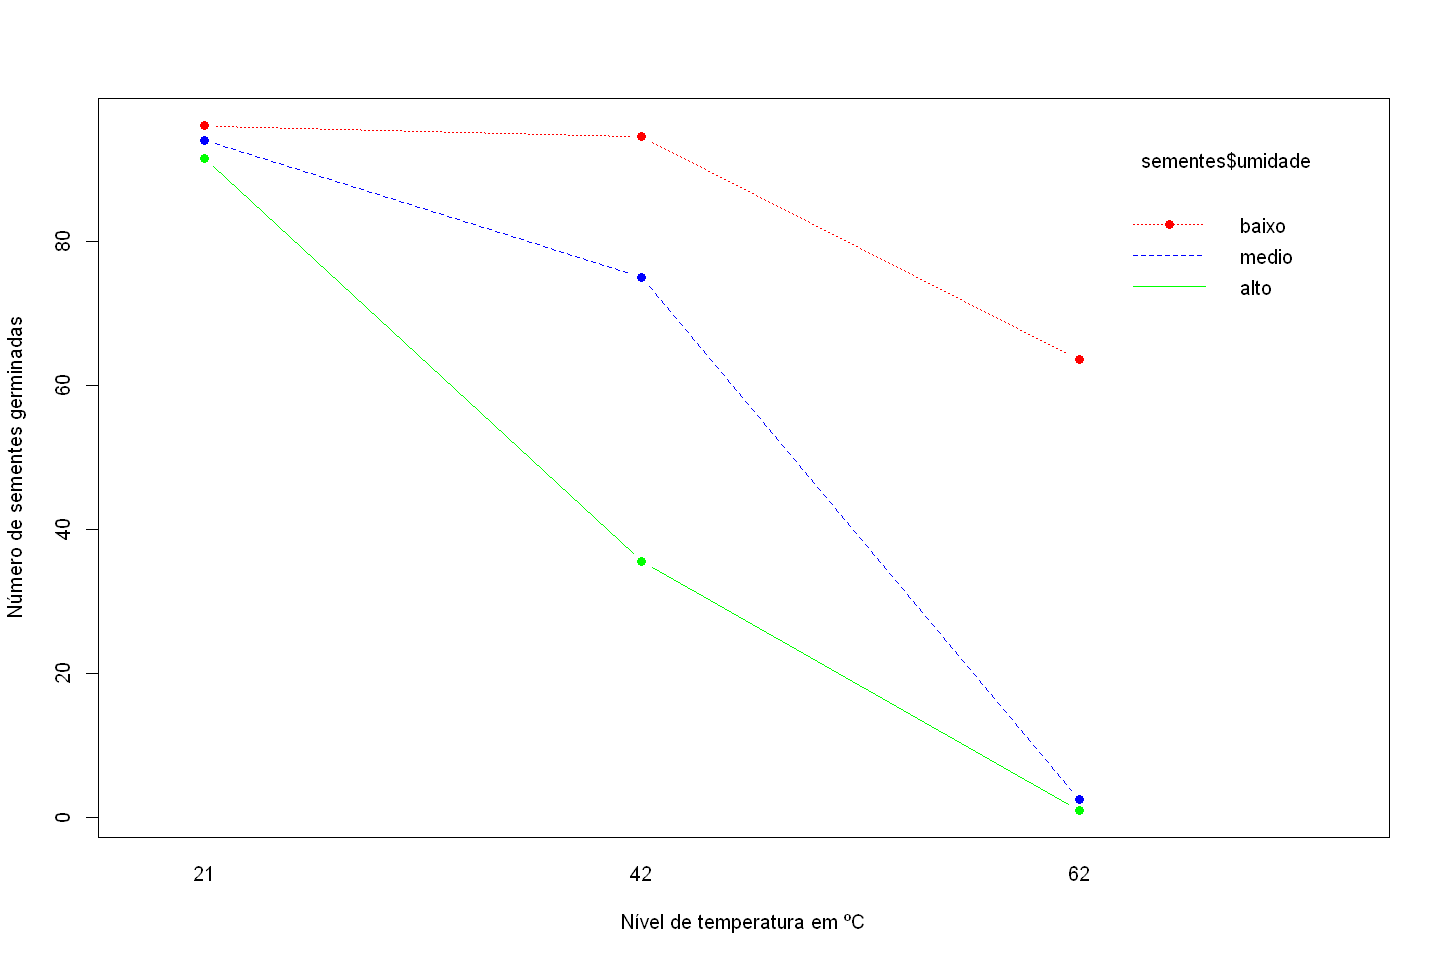

In [61]:
options(repr.plot.width = 12, repr.plot.height = 8)

interaction.plot(sementes$temp, sementes$umidade, sementes$nsg, type = "b", pch = 16, col = c("red", "blue", "green"), xlab = "Nível de temperatura em ºC", ylab = "Número de sementes germinadas", legend = TRUE)

Ausência de paralelismo no gráfico. Sinal meio forte de interação entre a **temperatura x umidade**. 

Outros comentários: 

- com  nível de temperatura 21ºC a taxa de germinação é alta;
- depois, em 42ºC a germinação cai quando a umidade tá alta ou média, enquanto a germinação é pouco afetada com baixa umidade; 
- -daí em 62ºC a germinação com umidade média ou alta a germinação despenca, enquanto isso com umidade baixa tem alguns sementes que germinam ainda.

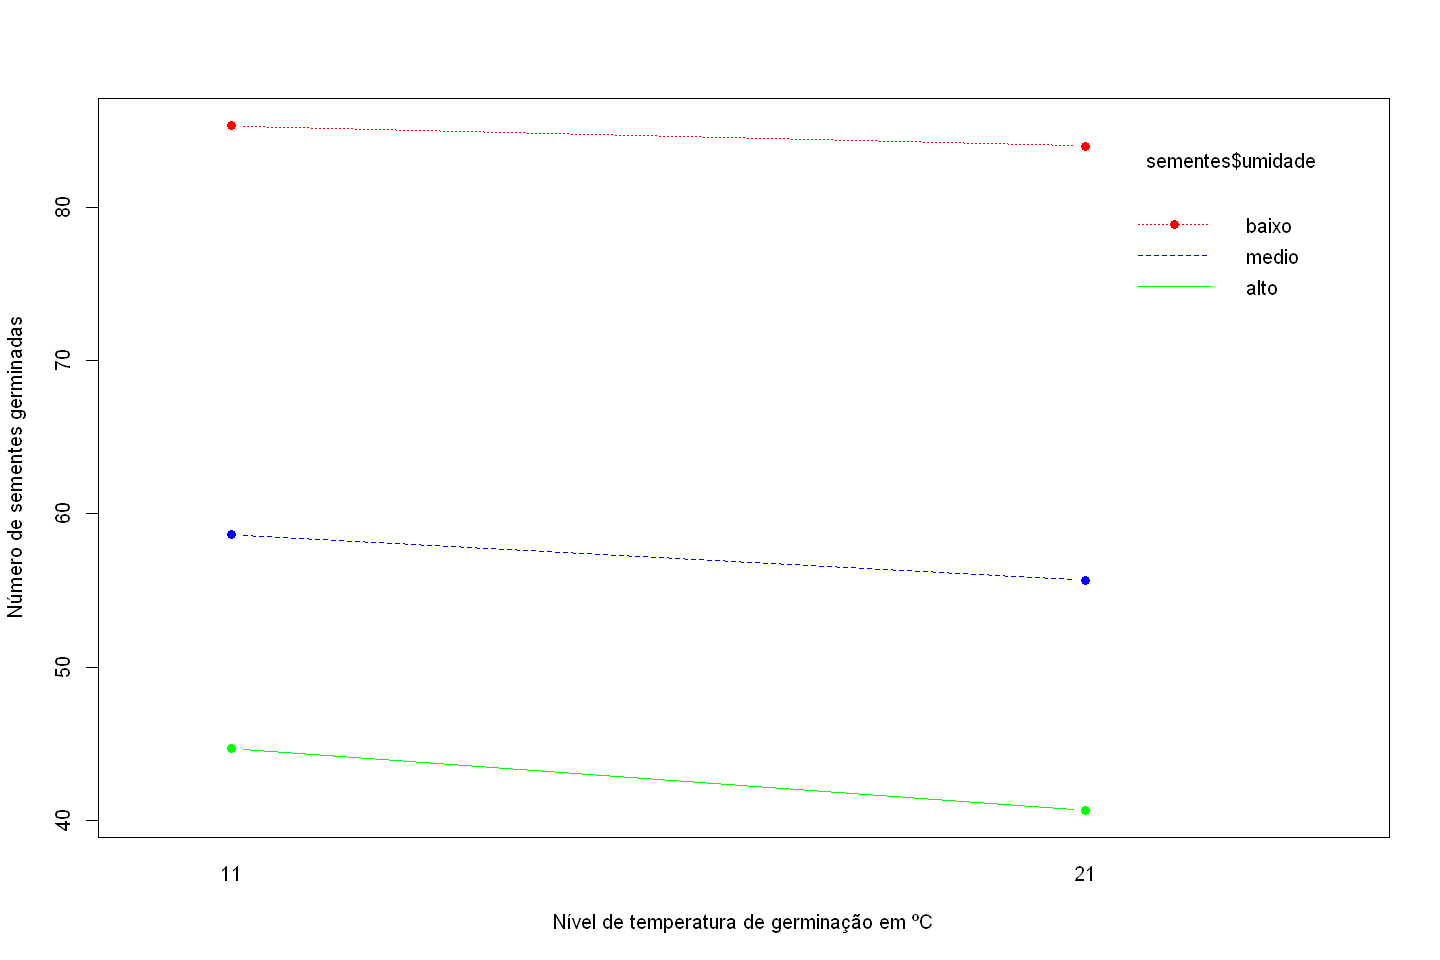

In [62]:
options(repr.plot.width = 12, repr.plot.height = 8)

interaction.plot(sementes$tempg, sementes$umidade, sementes$nsg, type = "b", pch = 16, col = c("red", "blue", "green"), xlab = "Nível de temperatura de germinação em ºC", ylab = "Número de sementes germinadas", legend = TRUE)

Vamos ver a interação de temperatura de germinação x umidade com o gráfico acima. Presença de paralelismo, aliás a inclinação é pequena. Isso quer dizer que temos pouca evidência de interação entre a temp de germinação e umidade e parece que o efeito é pequeno..

### 4.2  método aic para selecionar modelo. considerando interação de 1ª ordem

In [63]:
# vamos usar modelo binomial + ligação logit aqui, considerando que nsg é o num de sucesso e m - nsg é o num de fracasso. m = 100 pois cada combinação tem 100 sementes na amostra.
# fit0 é  o sem interação, e vamos usar stepAIC para ver se tem interaçãoentre elas. isso inclui os termos quadráticos também.
fit0.sementes <- glm(cbind(nsg, m - nsg) ~ tempg + umidade + temp, family = binomial(link = "logit"), data = sementes)

fit.sementes <- stepAIC(fit0.sementes,
                   scope = list(upper = ~ (tempg + umidade + temp)^2, lower = ~ 1),
                   direction = "both")


Start:  AIC=142.29
cbind(nsg, m - nsg) ~ tempg + umidade + temp

                Df Deviance     AIC
+ umidade:temp   4     4.43   91.53
<none>                63.19  142.29
- tempg          1    66.37  143.47
+ tempg:temp     2    60.51  143.61
+ tempg:umidade  2    62.95  146.05
- umidade        2   493.63  568.73
- temp           2   982.29 1057.40

Step:  AIC=91.53
cbind(nsg, m - nsg) ~ tempg + umidade + temp + umidade:temp

                Df Deviance     AIC
<none>                4.430  91.532
- tempg          1    7.880  92.983
+ tempg:temp     2    1.892  92.995
+ tempg:umidade  2    3.838  94.941
- umidade:temp   4   63.190 142.293


O algoritmo de stepwise (nos dois lados) nos recomendou que a interação entre a umidade e temperatura deve entrar no modelo. 

Comentários sobre os valores:
- no modelo de só efeitos principais, temos AIC de 142.3; e com interação o AIC tá 91.5; e adicionando outros termos não reduz AIC.
- note que no modelo recomendado, retirando a covariável `tempg` aumenta o AIC em 1.4 unidade apenas.


Vamos dizer que o modelo selecionado tem as seguintes covariavéis: tempg + umidade + temp + umidade:temp

### 4.3 analisando o modelo

In [64]:
summary(fit.sementes)


Call:
glm(formula = cbind(nsg, m - nsg) ~ tempg + umidade + temp + 
    umidade:temp, family = binomial(link = "logit"), data = sementes)

Coefficients:
                    Estimate Std. Error z value Pr(>|z|)    
(Intercept)           3.3251     0.3706   8.971  < 2e-16 ***
tempg21              -0.2765     0.1492  -1.853   0.0638 .  
umidademedio         -0.4269     0.4680  -0.912   0.3617    
umidadealto          -0.8026     0.4412  -1.819   0.0689 .  
temp42               -0.3345     0.4760  -0.703   0.4823    
temp62               -2.6305     0.3899  -6.747 1.51e-11 ***
umidademedio:temp42  -1.3220     0.5849  -2.260   0.0238 *  
umidadealto:temp42   -2.6496     0.5595  -4.736 2.18e-06 ***
umidademedio:temp62  -3.8020     0.6679  -5.693 1.25e-08 ***
umidadealto:temp62   -4.3581     0.8495  -5.130 2.89e-07 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 1230.8604  on 17  degrees of f

Temos que desvio = 4.43, com 8 g.l; 4.43/8 dá proximo de 0.55. Como em modelo binomial o $\phi$ é fixo igual a 1, esse 0.55 que é menor que 1 não significa falta ajuste. (Na vdd vimos que o D nesse caso dá assintoticamente uma qui-quadrado com 8 gl. e esse valor tá dentro do esperado. não temos evidências de falta de ajuste)

In [65]:
drop1(fit.sementes, test = "Chisq")

,Df,Deviance,AIC,LRT,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,4.429755,91.53238,NA,NA
tempg,1,7.880214,92.98284,3.450459,6.323422e-02
umidade:temp,4,63.190319,142.29294,58.760564,5.283205e-12


O TRV diz que:
- a interação umidade x temp é muito significativa (valor-p bem pequeno, 5e-12)
- tempg é não significativo ao nível de 5%. vamos manter no modelo por AIC.

### 4.4 Interpretação dos resultados.


In [66]:
grade <- expand.grid(tempg = levels(sementes$tempg), umidade = levels(sementes$umidade), temp = levels(sementes$temp))
grade$p_hat <- round(predict(fit.sementes, newdata = grade, type = "response"), 3)
xtabs(p_hat ~ umidade + temp + tempg, data = grade)


, , tempg = 11

       temp
umidade    21    42    62
  baixo 0.965 0.952 0.667
  medio 0.948 0.776 0.028
  alto  0.926 0.387 0.011

, , tempg = 21

       temp
umidade    21    42    62
  baixo 0.955 0.938 0.603
  medio 0.932 0.724 0.022
  alto  0.904 0.323 0.009



Temos

- coeficiente de tempg estimatido dá -0.277, então exp(-0.277) dá proximo de 0.76. ou seja, estima-se que, fixando a umidade e temperatura, a temperatura DE GERMINAÇÃO passar de 11 ºC para 21 ºC multiplica a chance de germinar a semente por 0.76, que é uma redução de 24% (embora isso não seja significativa). Como essa covariável não tem interação com nehuma outra, a interpretação vale para qualquer combinação de umidade x temp.

- umidade x temp: como temos interação, o efeito de um depende do outro. vamos olhar para as probabilidades estimadas que tá na tabela acima.:
  - em temperatura de  21 ºC, a germinação é alta (varia de 0.904 a 0.965), e pouco importa a umidade nessa temperatura.
  - em temperatura de 42 ºC, a umidade alta diminui muito a germinação (cai para por volta de 0.3); enquanto na umidade baixa a germinação é pouco afetada; e na umidade média cai um pouco mas nem tanto como em umidade alta.
  - em temperatura de 62 ºC, na umidade média e alta a germinação despenca (probabilidade bem baixa, por volta de 0.01 e 0.03) ; só com umidade baixa as plantinhas conseguem germinar (0.60 ~0.67).  

Daí se a gente for interpretar em termos de chances: Por exemplo (mantida a temperatura de germinação constante), fixando 62 ºC, a chance de germinar com umidade alta é $e^{-0{.}803 - 4{.}358}$ que dá 0.006 vezes menor em relação a referência (umiadde baixa); enquanto fixando 21 ºC a chance é apenas $e^{-0.803}$ que dá 0.45 vezes menor.

Comentário: então para ter uma germinação, recomenda-se dar um ambiente de temperatura baixa e/ou umidade baixa; a combinação de temperatura e umidade altas vão cozinha a coitada da semente.


### 4.5 Diagnóstico

Referência 2p/n = 1.111 


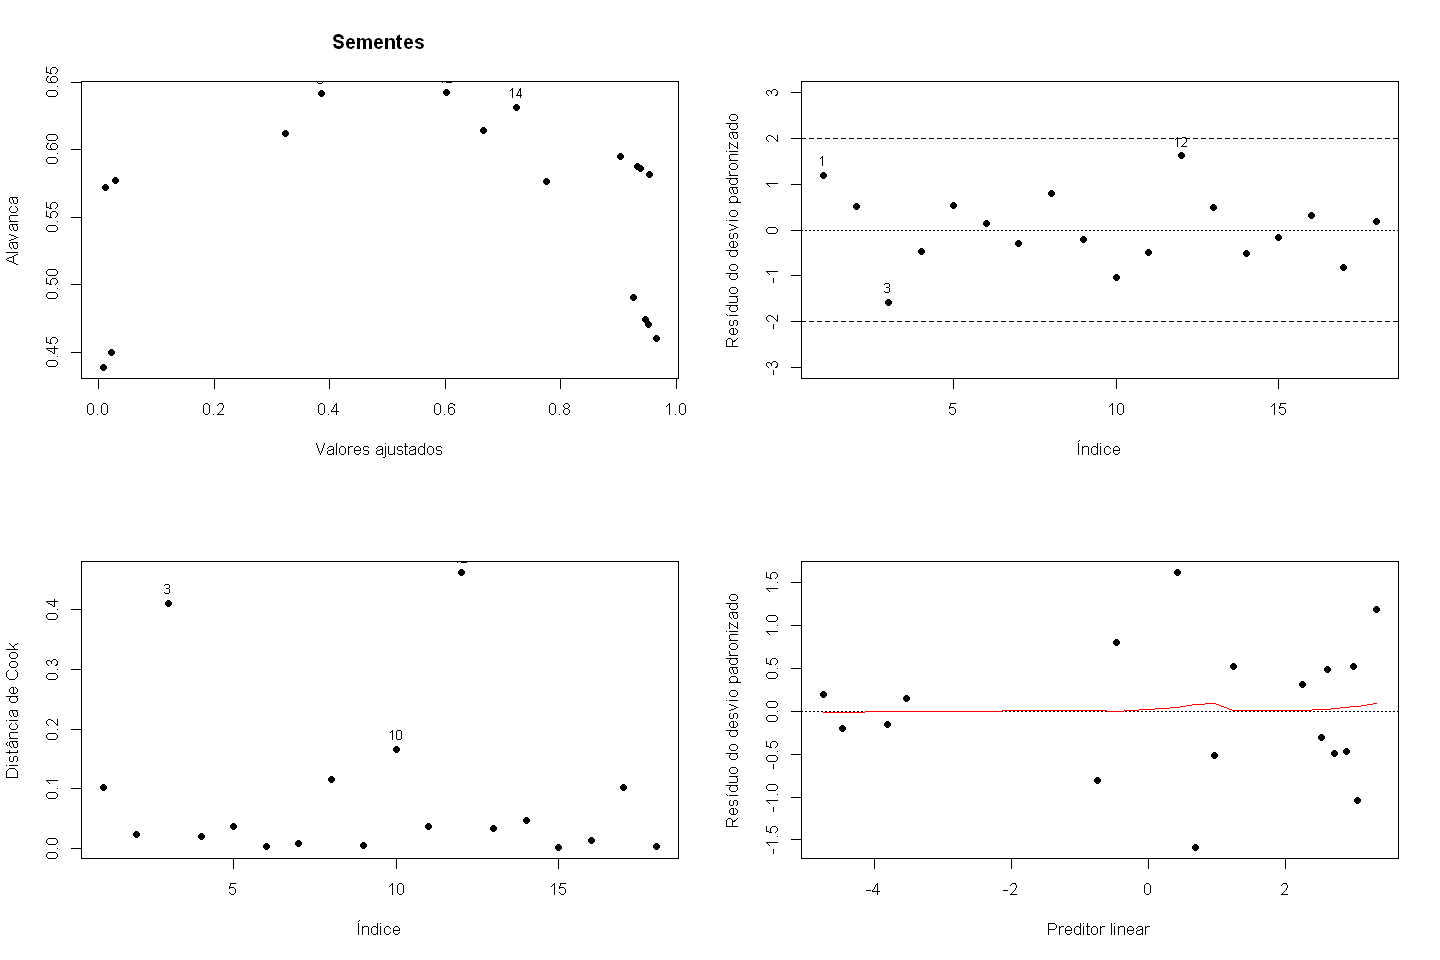

In [67]:
options(repr.plot.width = 12, repr.plot.height = 8)

ds <- diag_glm(fit.sementes,titulo = "Sementes")

Parece que ta tudo tranquilo. 

Pontos fora do envelope: 0 de 18 (0.0%)


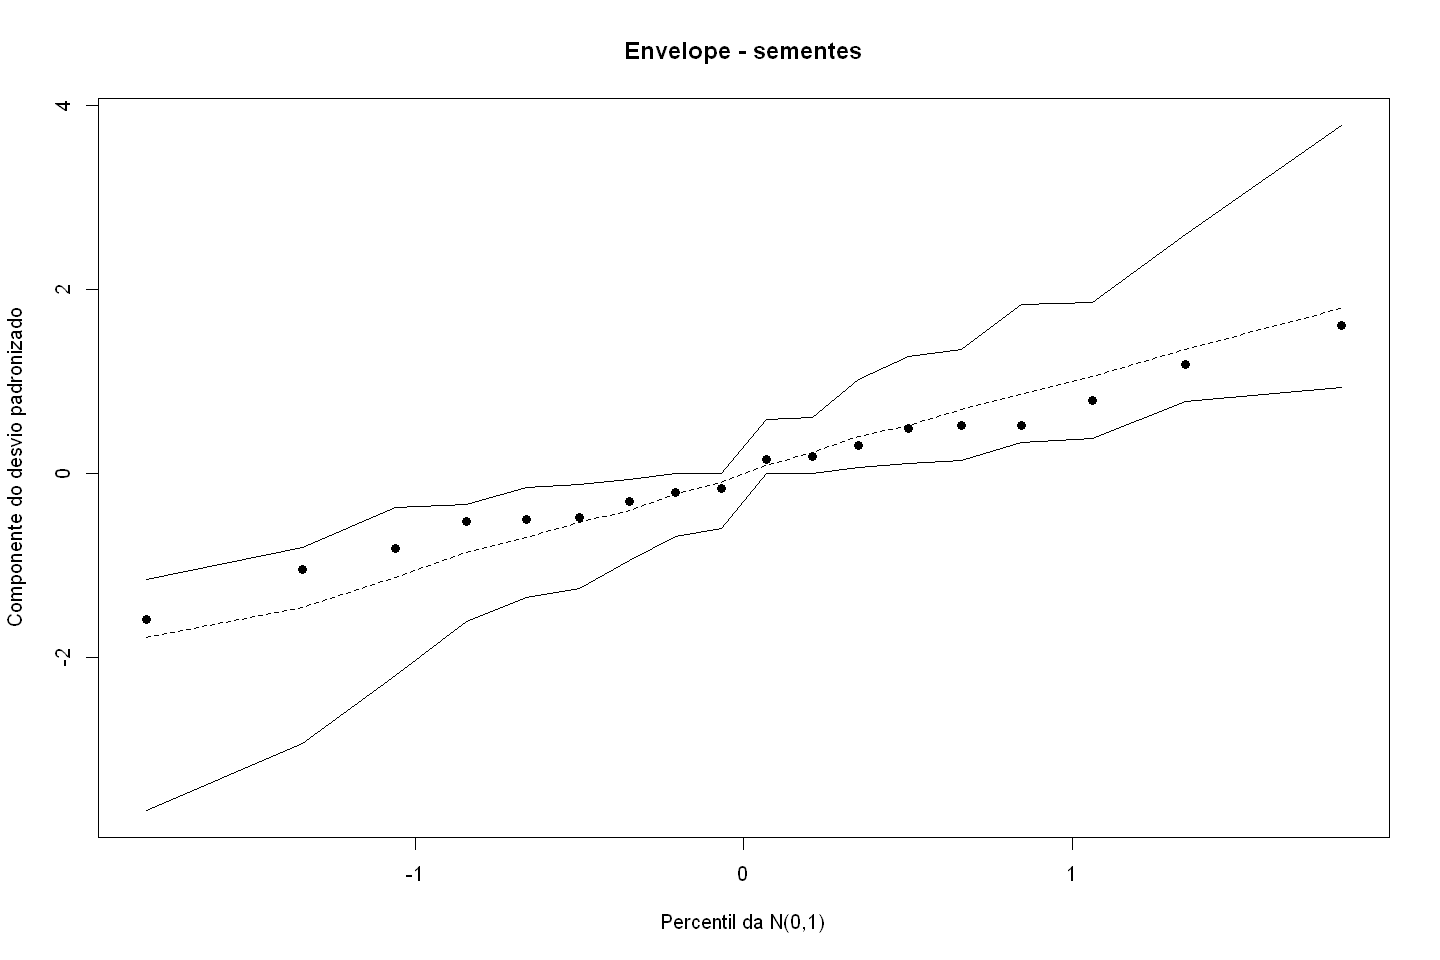

In [68]:
options(repr.plot.width = 12, repr.plot.height = 8)

envelope_glm(fit.sementes, main = "Envelope - sementes")


Todos os pontos dentro do envelope, ótimo. Modelo adequado (modelo boniminal, logistico, com interação de umidade x temperatura)

## Ex5

Faça ex 21 do cap4. use AIC ao invés de teste de hipótese como critério de stepwise.

Temos leuce.txt, pacientes adultos diagnosticados com leucemia (tipo AGUDO :O ); temos tratamentos, queremos ver a eficiência do tratamento (resposta binária: sim ou não). Covariáveis: idade;manda;infiltração;celulas; etc no total 9 delas, algumas continuas algumas em %, algumas categoricas. Considere modelo logistico linear para explicar a probabilidade de eficiencia de tratamento dadas as seis variáveis explicativas (as 3 últimas são relacionadas às respostas) ~~Selecione as variáveis explicativas como as interações de 1ª ordem com stepwise. Usar $P_E$ = $P_S$ = 0.2.~~ Fazer uma análise de diagnóstico com o modelo selecionado e interpretar algumas razões de chances. 

Com esses dados do enunciado vamos usar a distribuição bernoulli para modelar: $Y_i \sim Bernoulli(\pi_i)$, e logit($\pi_i$) = $x_i ^\top \beta$, onde $Y_i$ modela se o paciente acha se tratamento satisfatório ou não.

In [69]:
leucemia <- read.table(paste0(caminho,"L4-Q5-C4-EX21-leuce.txt"), header = TRUE, skip = 2) # skip = 2 pula duas linha pq por algum motivo tem duas linhas em branco

### 5.1 ADED

In [70]:
str(leucemia)
table(leucemia$trat)

'data.frame':	51 obs. of  9 variables:
 $ idade : int  20 25 26 26 27 27 28 28 31 33 ...
 $ mancha: int  78 64 61 64 95 80 88 70 72 58 ...
 $ infil : int  39 61 55 64 95 64 88 70 72 58 ...
 $ cel   : int  7 16 12 16 6 8 20 14 5 7 ...
 $ malig : num  0.6 35 7.5 21 7.5 0.6 4.8 10 2.3 5.7 ...
 $ temp  : int  990 1030 982 1000 980 1010 986 1010 988 986 ...
 $ trat  : int  1 1 1 1 1 0 1 1 1 0 ...
 $ tempo : int  18 31 31 31 36 1 9 39 20 4 ...
 $ sobrev: int  0 1 0 0 0 0 0 1 1 0 ...



 0  1 
27 24 

Temos 51 pacientes, para 24 deles o tratamento foi satisfatório, e para os outros 27 o tratamento não foi satisfatório. 

In [71]:
round(cor(leucemia[, 1:6]), 2)

,idade,mancha,infil,cel,malig,temp
idade,1.00,-0.20,-0.14,-0.12,0.05,0.08
mancha,-0.20,1.00,0.85,0.10,0.33,-0.03
infil,-0.14,0.85,1.00,0.14,0.34,-0.01
cel,-0.12,0.10,0.14,1.00,0.38,0.07
malig,0.05,0.33,0.34,0.38,1.00,0.36
temp,0.08,-0.03,-0.01,0.07,0.36,1.00


Matriz de correlação com as covariáveis contínuas. O mais notável é o par de mancha e infil, que tem uma correlação de 0.85, isso não é muito alarmante, mas pode ser que apenas uma delas entram no modelo.

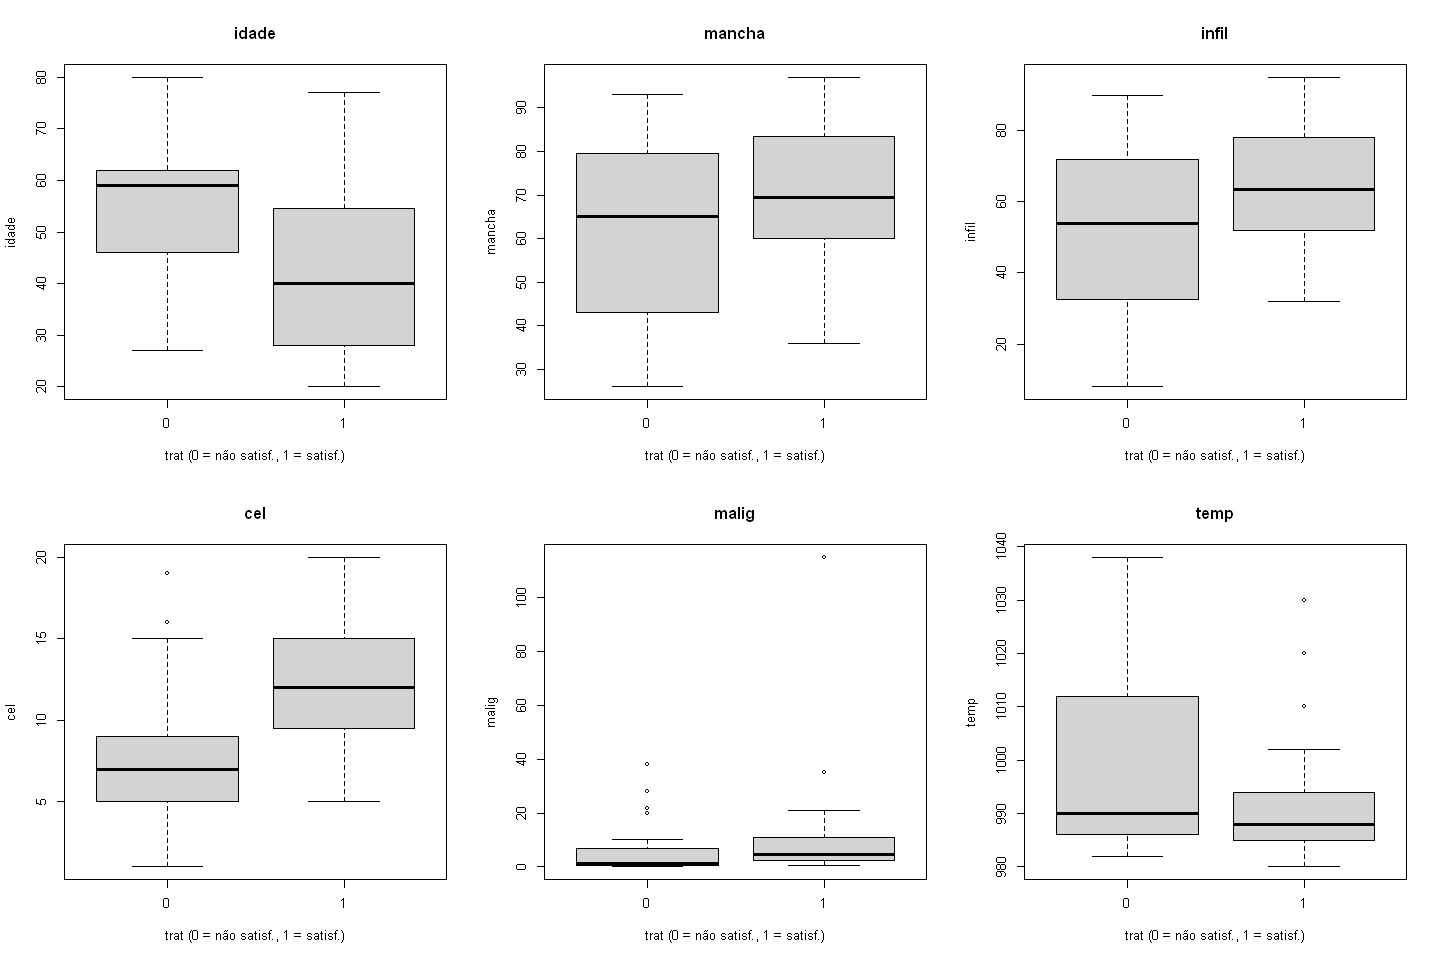

In [72]:
options(repr.plot.width = 12, repr.plot.height = 8)

par(mfrow = c(2, 3))
for (v in c("idade", "mancha", "infil", "cel", "malig", "temp"))
  boxplot(leucemia[[v]] ~ leucemia$trat, xlab = "trat (0 = não satisf., 1 = satisf.)", ylab = v, main = v)
par(mfrow = c(1, 1))


Nesses boxplots podemos ver que descritivamente os pacientes com tratamento satisfatótio tendem a: ser as pessoas jovens; ter mais células com leucemia (cel); e temperatura menor.

### 5.2 stepwise por AIC (de efeitos principais primeiro para ver quais devem ficar)

In [73]:
#modelo nulo sem covariáveis
nulo.leucemia <- glm(trat ~ 1, family = binomial, data = leucemia)

fit1.leucemia <- stepAIC(nulo.leucemia, scope = list(upper = ~ idade + mancha + infil + 
                cel + malig + temp, lower = ~1),
                direction = "both")
summary(fit1.leucemia)

Start:  AIC=72.52
trat ~ 1

         Df Deviance    AIC
+ cel     1   57.119 61.119
+ idade   1   64.004 68.004
+ temp    1   66.766 70.766
+ infil   1   66.849 70.849
+ mancha  1   68.117 72.117
+ malig   1   68.323 72.323
<none>        70.524 72.524

Step:  AIC=61.12
trat ~ cel

         Df Deviance    AIC
+ temp    1   49.645 55.645
+ idade   1   51.387 57.387
+ infil   1   54.158 60.158
+ mancha  1   54.980 60.980
<none>        57.119 61.119
+ malig   1   57.080 63.080
- cel     1   70.524 72.524

Step:  AIC=55.65
trat ~ cel + temp

         Df Deviance    AIC
+ idade   1   43.265 51.265
+ infil   1   46.438 54.438
+ mancha  1   46.835 54.835
+ malig   1   47.492 55.492
<none>        49.645 55.645
- temp    1   57.119 61.119
- cel     1   66.766 70.766

Step:  AIC=51.27
trat ~ cel + temp + idade

         Df Deviance    AIC
+ infil   1   40.136 50.136
+ malig   1   41.042 51.042
+ mancha  1   41.222 51.222
<none>        43.265 51.265
- idade   1   49.645 55.645
- temp    1   51.387


Call:
glm(formula = trat ~ cel + temp + idade + infil, family = binomial, 
    data = leucemia)

Coefficients:
            Estimate Std. Error z value Pr(>|z|)   
(Intercept) 95.56766   38.59482   2.476  0.01328 * 
cel          0.40673    0.13034   3.121  0.00181 **
temp        -0.09944    0.03954  -2.515  0.01191 * 
idade       -0.06026    0.02678  -2.250  0.02445 * 
infil        0.03413    0.02079   1.641  0.10077   
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 70.524  on 50  degrees of freedom
Residual deviance: 40.136  on 46  degrees of freedom
AIC: 50.136

Number of Fisher Scoring iterations: 6


Partindo do modelo nulo vimos que o modelo escolhido por stepwise inclui `cel`, `temp`, `idade`, `infil`, e seu AIC é aproximadamente 50.1; as covariáveis `mancha` e `malig` não entram.

### 5.3 stepwise por AIC (agora com as interações de 1ª ordem)


In [75]:
fit2.leucemia <- stepAIC(fit1.leucemia, scope = list(upper = ~ (idade + infil + cel + temp)^2, lower = ~1), direction = "both")

summary(fit2.leucemia)

anova(fit1.leucemia, fit2.leucemia, test = "Chisq")


Start:  AIC=50.14
trat ~ cel + temp + idade + infil

              Df Deviance    AIC
+ infil:temp   1   37.599 49.599
<none>             40.136 50.136
- infil        1   43.265 51.265
+ cel:temp     1   39.435 51.435
+ idade:infil  1   39.671 51.671
+ infil:cel    1   39.891 51.891
+ idade:cel    1   39.895 51.895
+ idade:temp   1   40.136 52.136
- idade        1   46.438 54.438
- temp         1   48.971 56.971
- cel          1   57.602 65.602

Step:  AIC=49.6
trat ~ cel + temp + idade + infil + temp:infil

              Df Deviance    AIC
+ idade:infil  1   35.462 49.462
<none>             37.599 49.599
- temp:infil   1   40.136 50.136
+ idade:temp   1   37.211 51.211
+ infil:cel    1   37.308 51.308
+ cel:temp     1   37.552 51.552
+ idade:cel    1   37.579 51.579
- idade        1   43.746 53.746
- cel          1   57.586 67.586

Step:  AIC=49.46
trat ~ cel + temp + idade + infil + temp:infil + idade:infil

              Df Deviance    AIC
<none>             35.462 49.462
- idade:in


Call:
glm(formula = trat ~ cel + temp + idade + infil + temp:infil + 
    idade:infil, family = binomial, data = leucemia)

Coefficients:
              Estimate Std. Error z value Pr(>|z|)   
(Intercept) -1.640e+02  1.294e+02  -1.268   0.2050   
cel          6.156e-01  2.036e-01   3.024   0.0025 **
temp         1.671e-01  1.311e-01   1.274   0.2026   
idade       -2.109e-01  1.150e-01  -1.834   0.0666 . 
infil        4.516e+00  2.255e+00   2.003   0.0452 * 
temp:infil  -4.628e-03  2.305e-03  -2.008   0.0446 * 
idade:infil  2.386e-03  1.727e-03   1.382   0.1671   
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 70.524  on 50  degrees of freedom
Residual deviance: 35.462  on 44  degrees of freedom
AIC: 49.462

Number of Fisher Scoring iterations: 6


,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,46,40.13624,NA,NA,NA
2,44,35.46231,2,4.673929,0.09662047


O stepwise escolheu incluir duas interações no modelo, o `tempo:infil` e `idade: infil` ; porém o ganho é pouco, o AIC foi de 50.1 para 49.5. E a interação `idade:infil` não é significativo pela saida de summary. O TRV diz que não temos evidências para dizer que as duas interações são importantes no modelo.

Vamos ficar com o modelo de efeitos principais apenas: trat ~idade + infil + cel + tempo

In [76]:
fit.leucemia <- glm(trat ~ idade + infil + cel + temp, family = binomial, data = leucemia)
summary(fit.leucemia)   


Call:
glm(formula = trat ~ idade + infil + cel + temp, family = binomial, 
    data = leucemia)

Coefficients:
            Estimate Std. Error z value Pr(>|z|)   
(Intercept) 95.56766   38.59482   2.476  0.01328 * 
idade       -0.06026    0.02678  -2.250  0.02445 * 
infil        0.03413    0.02079   1.641  0.10077   
cel          0.40673    0.13034   3.121  0.00181 **
temp        -0.09944    0.03954  -2.515  0.01191 * 
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 70.524  on 50  degrees of freedom
Residual deviance: 40.136  on 46  degrees of freedom
AIC: 50.136

Number of Fisher Scoring iterations: 6


Com essas saídas o modelo fica assim:

$$\text{logit}(\hat\pi) = 95{,}57 - 0{,}060\,\text{idade} + 0{,}034\,\text{infil} + 0{,}407\,\text{cel} - 0{,}099\,\text{temp}.$$

Além disso temos desvio = 40.1, com 46 de gl; e não temos interpretação de intercepto...

### 5.4 diagnóstico

Referência 2p/n = 0.196 


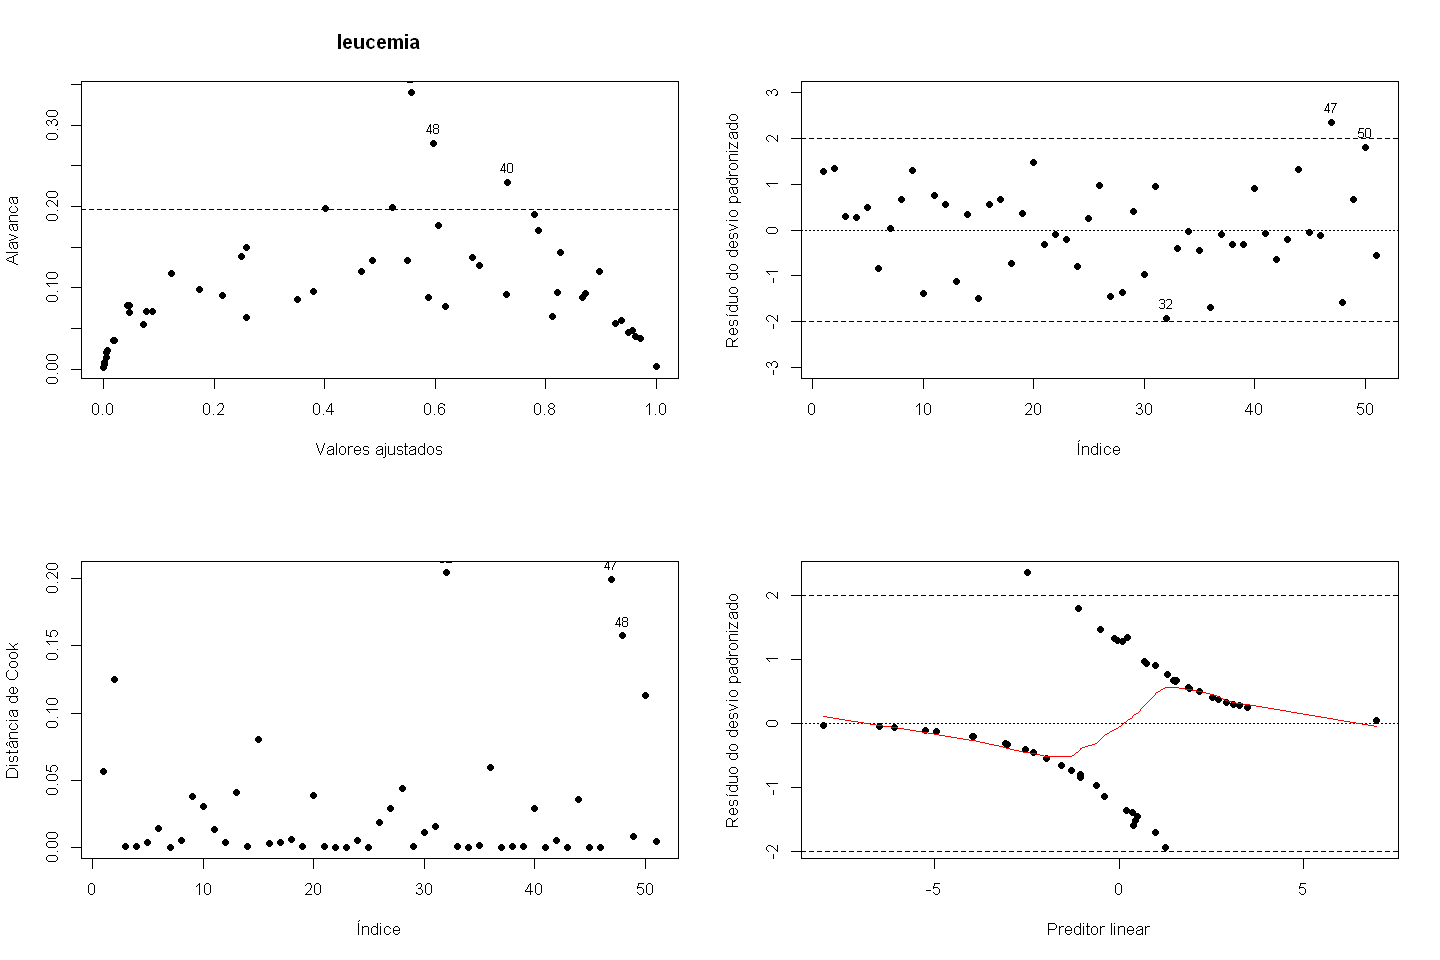

In [77]:
diag_leucemia <- diag_glm(fit.leucemia, titulo = "leucemia")

In [78]:
head(sort(hatvalues(fit.leucemia), decreasing = TRUE))

2        48        40         1        13        32 
0.3400564 0.2775425 0.2296748 0.1983515 0.1975675 0.1898010

In [79]:
head(sort(rstandard(fit.leucemia), decreasing = TRUE))


47       50       20        2       44        9 
2.350919 1.797821 1.465392 1.333489 1.317135 1.291851

In [80]:
head(sort(cooks.distance(fit.leucemia), decreasing = TRUE))


32        47        48         2        50        15 
0.2044242 0.1995769 0.1573211 0.1246370 0.1128807 0.0805032

comentários:

- alavanca: temos 2 pontos notáveis, o 2 e 48.
- resíduos: só o 47 tá notável
- cook: as maiores são 32; 47; e 48.

não temos uma situação muito alarmante aqui

Pontos fora do envelope: 0 de 51 (0.0%)


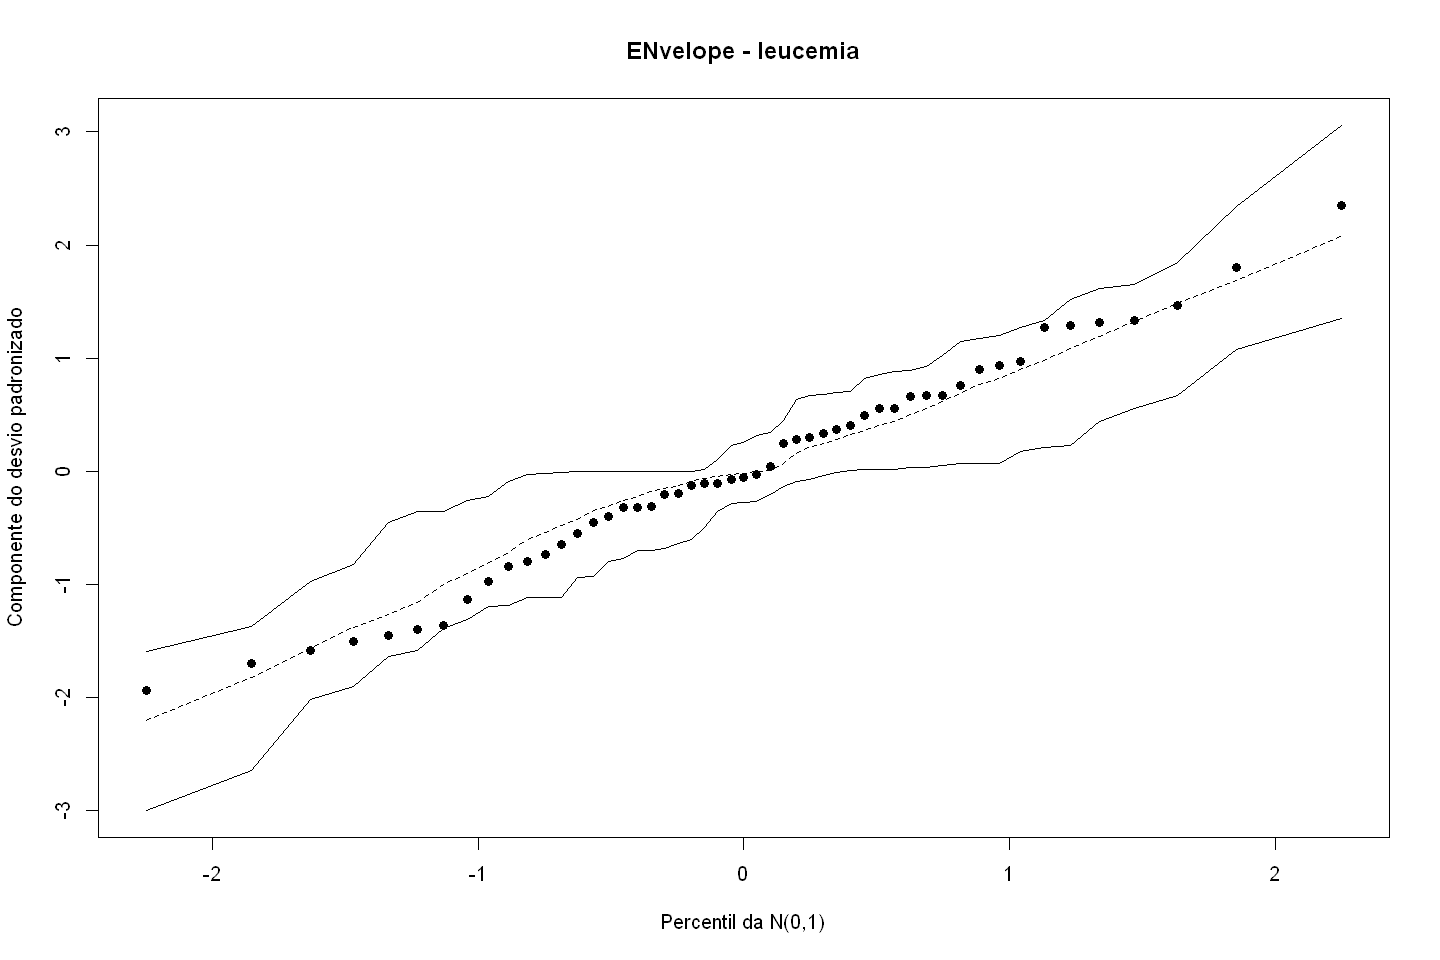

In [81]:
envelope_glm(fit.leucemia, main = "ENvelope - leucemia")

Pontos dentro do envelope, ótimo. Parece que o modelo tá bem ajustado

#### Verificando a sensibilidade do modelo

In [ ]:
for (k in c(32, 47, 48)) {
  ajk <- glm(trat ~ idade + infil + cel + temp, family = binomial, data = leucemia, subset = -k)
  cat("\nSem a observação", k, "- variação % das estimativas e p-valores:\n")
  print(round(cbind(var_pct = (coef(ajk) - coef(fit.leucemia)) / coef(fit.leucemia) * 100,
                    p_valor = summary(ajk)$coefficients[, 4]), 3))
}


Sem a observação 32 - variação % das estimativas e p-valores:
            var_pct p_valor
(Intercept) -11.631   0.039
idade        -3.516   0.035
infil        28.094   0.057
cel          16.913   0.001
temp        -10.010   0.032

Sem a observação 47 - variação % das estimativas e p-valores:
            var_pct p_valor
(Intercept)  37.454   0.009
idade        51.548   0.011
infil        25.718   0.074
cel          28.364   0.003
temp         36.654   0.008

Sem a observação 48 - variação % das estimativas e p-valores:
            var_pct p_valor
(Intercept)  11.786   0.011
idade       -13.442   0.053
infil       -24.951   0.216
cel          14.616   0.002
temp         11.745   0.009


eita. Retirando uma de cada vez as observações mais influentes, as estimativas dos coeficientes mudam bastante (até 50% no de idade sem a obs 47). Mesmo assim os sinais dos coeficientes estimados não mudam, e eles continuam significativos no modelo (excetoo `infil`). Vamos manter todas observações.

### 5.5 razões de chances

In [85]:
or <- exp(cbind(OR = coef(fit.leucemia), confint.default(fit.leucemia)))[-1, ]
round(or, 3)

# razões de chances para incrementos mais interpretáveis
# idade é em cada 10 anos, infil em cada 10%, cel em cada 5% e temp em cada 10ºF
inc <- c(idade = 10, infil = 10, cel = 5, temp = 10)
round(exp(inc * cbind(coef(fit.leucemia)[names(inc)], confint.default(fit.leucemia)[names(inc), ])), 3)

,OR,2.5 %,97.5 %
idade,0.942,0.893,0.992
infil,1.035,0.993,1.078
cel,1.502,1.163,1.939
temp,0.905,0.838,0.978


,,2.5 %,97.5 %
idade,0.547,0.324,0.925
infil,1.407,0.936,2.115
cel,7.642,2.130,27.412
temp,0.370,0.170,0.803


Como não temos interação, a interpretação fica fácil. 

- idade: (mantida as outras constantes) razão de chance por ano é próximo de 0.94. Daí estima-se que para cada 10 anos a mais a chance de sucesso é multimplicado por 0.94^10 = 0.55, ou seja chance de 45% a menos para ter tratamento satisfatório
- infil: (mantida as outras constantes) estima-se que cada 10 pontos percentuais a mais multiplica a chance do ter tratamento satisfatório por 1.4, porém o efeito não foi significativo ao nível de 5%
- cel: (mantida as outras constantes) razão de chance por ponto percentual é ~ 1.5. Multiplicando por 5 dá próximo 7.6. Pacientes que tem mais celulas com leucemia tendem a responder melhor com o tratamento
- temp: (mantida as outras constantes) razão de chance por cada décimo de graus de fahrenheit é 0.905, então por grau de fahrenheit fica 0.37. Estima-se que cada 1ºF a mais na temperatura maxima multiplica a chance por 0.37. Ou seja febre alta antes do tratamento reduz a chance de sucesso